In [ ]:
import pathlib
import random
import re
import warnings

import alifedata_phyloinformatics_convert as apc
from hstrat import _auxiliary_lib as hstrat_aux
import iplotx as ipx
import marimo as mo
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from phyloframe import legacy as pfl
import polars as pl
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from watermark import watermark

from pylib import osf_fetch, percentileofscore_grouped

warnings.filterwarnings("ignore", category=DeprecationWarning)
# Computer Modern math, e.g., for italic site class qualifiers
plt.rcParams["mathtext.fontset"] = "cm"

OSF_SLUGS = ("th7nw", "4rwqu", "w5yvk", "zujds")
NUM_SITES = 16
ALPHA = 0.05
MAX_TREE_LEAVES = 4000
SEED = 1
# dark, middle, and light shades per site class; plots use the middle
ETI_PALETTE = {
    "MLS": ["#004C7A", "#0072B2", "#8FC3E6"],
    "BENwg": ["#00664F", "#009E73", "#8ED6BE"],
    "DELbg": ["#9A3F00", "#D55E00", "#F2B48A"],
    "neutral": ["#6E6E6E", "#A6A6A6", "#DADADA"],
}

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/alifedata_phyloinformatics_convert/_impl/phytrack_Systematcs.py:7: UserWarning: ImportWarning: phylotrackpy.Systematics import failed; inserting a no-op mock for Systematics. This is likely because phylotrackpy is not installed.
  warnings.warn(


In [ ]:
def gap_points(*artists):
    """Draw point-plot markers as gaps in their connecting lines, layered as:
    connecting line, white gap, error bar, white halo, then a small dot
    marking each position."""
    for artist in artists:
        if artist is None:
            continue
        for line in [*artist.get_lines()]:
            if line.get_marker() in ("None", None, ""):
                line.set_zorder(3)  # error bars (and reference lines)
                continue
            _is_axes = hasattr(artist, "plot")
            if not _is_axes:
                # legend entries: just a dot
                line.set_linestyle("none")
                line.set_markerfacecolor(line.get_color())
                line.set_markersize(7)
                line.set_markeredgewidth(0)
                continue
            # connecting line below a white gap
            line.set_zorder(1)
            if not len(line.get_xdata()):
                continue
            _xy = line.get_xdata(), line.get_ydata()
            artist.plot(
                *_xy,
                linestyle="none",
                marker="o",
                markersize=9,
                markeredgewidth=0,
                color="white",
                zorder=2,
            )
            line.set_marker("None")
            # white halo, then small dot, above the error bar
            for _size, _color, _z in (
                (3.6, "white", 4),
                (2.2, line.get_color(), 5),
            ):
                artist.plot(
                    *_xy,
                    linestyle="none",
                    marker="o",
                    markersize=_size,
                    markeredgewidth=0,
                    color=_color,
                    zorder=_z,
                )

In [ ]:
def effect_pct(effect):
    """Express an effect size label as a percent, passing "neu" through."""
    return (
        effect
        if effect in ("neu", "neutral")
        else f"{float(effect) * 100:.1f}"
    )

In [ ]:
def top_legend(g, title=None):
    """Replace a FacetGrid's legend with a single-row legend above the plot,
    with the title (if any) as a leading dummy entry."""
    _handles = [*g.legend.legend_handles]
    _labels = [_text.get_text() for _text in g.legend.get_texts()]
    g.legend.remove()
    g._legend = None
    # reclaim the space reserved for the old side legend
    g.tight_layout()
    if title is not None:
        _handles.insert(0, plt.Line2D([], [], linestyle="none"))
        _labels.insert(0, title)
    # center over the panels, rather than the whole figure
    _boxes = [_ax.get_position() for _ax in g.axes.flat]
    _left = min(_b.x0 for _b in _boxes)
    _right = max(_b.x1 for _b in _boxes)
    _renderer = g.figure.canvas.get_renderer()
    _span = (_right - _left) * g.figure.bbox.width
    # tighten entry spacing as needed so the legend doesn't overhang
    for _spacing in (2.5, 2.0, 1.5, 1.2, 1.0, 0.8, 0.6, 0.4):
        _legend = g.figure.legend(
            _handles,
            _labels,
            loc="lower center",
            bbox_to_anchor=((_left + _right) / 2, 1.0),
            ncol=len(_handles),
            frameon=False,
            handletextpad=0.5,
            columnspacing=_spacing,
        )
        if title is not None:
            # collapse the dummy entry's empty handle slot, so the title
            # sits flush and the legend's visible content is centered
            _first_row = _legend._legend_handle_box.get_children()[
                0
            ].get_children()[0]
            _first_row.get_children()[0].width = 0
        if _legend.get_window_extent(_renderer).width <= _span:
            break
        _legend.remove()

In [ ]:
def right_legend(g):
    """Replace a FacetGrid's legend with a single-column legend to the right
    of the panels, vertically centered on them."""
    _handles = [*g.legend.legend_handles]
    _labels = [_text.get_text() for _text in g.legend.get_texts()]
    g.legend.remove()
    g._legend = None
    g.tight_layout()
    _boxes = [_ax.get_position() for _ax in g.axes.flat]
    return g.figure.legend(
        _handles,
        _labels,
        loc="center left",
        bbox_to_anchor=(
            max(_b.x1 for _b in _boxes) + 0.02,
            (min(_b.y0 for _b in _boxes) + max(_b.y1 for _b in _boxes)) / 2,
        ),
        ncol=1,
        frameon=False,
        handlelength=0.8,
        handletextpad=0.5,
        labelspacing=1.0,
    )

In [ ]:
def corner_xlabel(g, legend, text="Effect\nSize (%)"):
    """Place the x axis label at bottom right, left-aligned under the legend
    and level with the bottom of the bottom-left panel's tick labels."""
    _renderer = g.figure.canvas.get_renderer()
    _to_fig = g.figure.transFigure.inverted()
    _ticks = [
        _t.get_window_extent(_renderer).transformed(_to_fig)
        for _t in g.axes.flat[-2].get_xticklabels()
    ]
    g.figure.text(
        legend.get_window_extent(_renderer).transformed(_to_fig).x0,
        min(_b.y0 for _b in _ticks),
        text,
        ha="left",
        va="bottom",
        fontsize=plt.rcParams["axes.labelsize"],
    )

In [ ]:
mo.md(f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
""")

```Text
Last updated: 2026-10-26T03:05:07.496516+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 7.31.1

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 6.17.0-1022-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

hstrat                            : 1.25.2
alifedata_phyloinformatics_convert: 0.19.3
marimo                            : 0.23.2
iplotx                            : 1.8.0
pandas                            : 2.2.3
numpy                             : 2.1.2
seaborn                           : 0.13.2
matplotlib                        : 3.10.9
phyloframe                        : 0.12.2
teeplot                           : 1.4.2
polars                            : 1.36.1
scipy                             : 1.14.1
re                                : 2.2.1

```

In [ ]:
mo.md(f"""
# MLS Spectrum Subgrid Fossils: Detectability by Population Size, Effect Size, and Site Class

Applies the phylogeny-based multilevel selection (MLS) screen from *Extending a Phylogeny-based Method for Detecting Signatures of Multi-level Selection for Applications in Artificial Life* (ISAL 2025, <https://doi.org/10.1162/ISAL.a.916>; code at <https://github.com/mmore500/multilevel-selection-concept>) to wafer-scale evolution data, following `2026-10-18-mls-spectrum-subgrid-fossils` and `2026-10-23-mlsindivspectra`.

Data were generated by [`wse-async-ga` `wsclust/2026-10-25-mls-spectrum-subgrid-fossils`](https://github.com/mmore500/wse-async-ga/tree/mlsspectrum-2026-10-25/wsclust/2026-10-25-mls-spectrum-subgrid-fossils) and are hosted at {", ".join(f"<https://osf.io/{slug}>" for slug in OSF_SLUGS)}.
Each file is one run's minified hstrat-reconstructed phylogeny (`06-minify-keep-pe-phylo` output), for subgrid sizes 0 (i.e., the full grid), 27, 81, and 243.
This minification collapses monomorphic clades only among genomes on the same processing element (PE), so each tip keeps a single PE location.
Fossils were collected by snapshot sampling.

Runs use genome flavor `genome_mlsspectrum_2026_10_25`, which combines the tile-population mechanics of `genome_mlsspectrum_2026_10_15` with the site layout of `genome_mlsindivspectra_2026_10_23`.
The genome carries three spectra of four sites each, with effect sizes $s_i \\in [0.05, 0.025, 0.01, 0.005]$, plus four neutral sites:

- **MLS** sites (`MLS`) are both favored within a tile population and harmful to recolonizing other tiles,
- **between-group deleterious** sites (`DELbg`) are only harmful to recolonizing other tiles, and
- **within-group beneficial** sites (`BENwg`) are only favored within a tile population.

Labels follow the ETI framework, with evaluation bar notation giving each trait's between-group effect above and within-group effect below, and $\\varnothing$ for no effect: MLS $|^{{-}}_{{+}}$, DELbg $|^{{-}}_{{\\varnothing}}$, BENwg $|^{{\\varnothing}}_{{+}}$, and neutral sites NEU $|^{{\\varnothing}}_{{\\varnothing}}$.

Each tile population goes extinct with probability 0.01, and only extinct tiles accept immigrants, so genes move between tiles only by recolonization.
An immigrant carrying a between-group deleterious site is blocked (clobbered) from recolonizing with probability $s_i$ per site, leaving the tile open to later immigrants.
A within-group beneficial site gives relative fitness $1 + s'_i$ in size-2 tournaments, with $s'_i = (1 + s_i)^{{\\log_2(N) / 25}} - 1$ rescaled to tile population size $N$.
Runs sweep subgrid size, where subgrids are blocks of tiles between which migration is disabled.

Each subgrid is an isolated metapopulation, so populations are analyzed independently rather than pooled: within each population, the screen asks whether each focal (MLS, deleterious, or beneficial) site

1. gives rise to more mutation-defined clades (MDCs) than expected for a neutral site (mutation-frequency screen), and
2. gives rise to MDCs that are smaller, shorter-lived, and/or spread over fewer PEs than neutral-site MDCs (clade-fitness screen).

Detectability is the fraction of populations in which a screen is significant at $\\alpha = {ALPHA}$, broken down by population size, site class, and effect size.
As a null calibration, the same screens are applied to each of the four neutral sites, against the other neutral sites.
""")

# MLS Spectrum Subgrid Fossils: Detectability by Population Size, Effect Size, and Site Class

Applies the phylogeny-based multilevel selection (MLS) screen from *Extending a Phylogeny-based Method for Detecting Signatures of Multi-level Selection for Applications in Artificial Life* (ISAL 2025, <https://doi.org/10.1162/ISAL.a.916>; code at <https://github.com/mmore500/multilevel-selection-concept>) to wafer-scale evolution data, following `2026-10-18-mls-spectrum-subgrid-fossils` and `2026-10-23-mlsindivspectra`.

Data were generated by [`wse-async-ga` `wsclust/2026-10-25-mls-spectrum-subgrid-fossils`](https://github.com/mmore500/wse-async-ga/tree/mlsspectrum-2026-10-25/wsclust/2026-10-25-mls-spectrum-subgrid-fossils) and are hosted at <https://osf.io/th7nw>, <https://osf.io/4rwqu>, <https://osf.io/w5yvk>, <https://osf.io/zujds>.
Each file is one run's minified hstrat-reconstructed phylogeny (`06-minify-keep-pe-phylo` output), for subgrid sizes 0 (i.e., the full grid), 27, 81, and 243.
This minification collapses monomorphic clades only among genomes on the same processing element (PE), so each tip keeps a single PE location.
Fossils were collected by snapshot sampling.

Runs use genome flavor `genome_mlsspectrum_2026_10_25`, which combines the tile-population mechanics of `genome_mlsspectrum_2026_10_15` with the site layout of `genome_mlsindivspectra_2026_10_23`.
The genome carries three spectra of four sites each, with effect sizes $s_i \in [0.05, 0.025, 0.01, 0.005]$, plus four neutral sites:

- **MLS** sites (`MLS`) are both favored within a tile population and harmful to recolonizing other tiles,
- **between-group deleterious** sites (`DELbg`) are only harmful to recolonizing other tiles, and
- **within-group beneficial** sites (`BENwg`) are only favored within a tile population.

Labels follow the ETI framework, with evaluation bar notation giving each trait's between-group effect above and within-group effect below, and $\varnothing$ for no effect: MLS $|^{-}_{+}$, DELbg $|^{-}_{\varnothing}$, BENwg $|^{\varnothing}_{+}$, and neutral sites NEU $|^{\varnothing}_{\varnothing}$.

Each tile population goes extinct with probability 0.01, and only extinct tiles accept immigrants, so genes move between tiles only by recolonization.
An immigrant carrying a between-group deleterious site is blocked (clobbered) from recolonizing with probability $s_i$ per site, leaving the tile open to later immigrants.
A within-group beneficial site gives relative fitness $1 + s'_i$ in size-2 tournaments, with $s'_i = (1 + s_i)^{\log_2(N) / 25} - 1$ rescaled to tile population size $N$.
Runs sweep subgrid size, where subgrids are blocks of tiles between which migration is disabled.

Each subgrid is an isolated metapopulation, so populations are analyzed independently rather than pooled: within each population, the screen asks whether each focal (MLS, deleterious, or beneficial) site

1. gives rise to more mutation-defined clades (MDCs) than expected for a neutral site (mutation-frequency screen), and
2. gives rise to MDCs that are smaller, shorter-lived, and/or spread over fewer PEs than neutral-site MDCs (clade-fitness screen).

Detectability is the fraction of populations in which a screen is significant at $\alpha = 0.05$, broken down by population size, site class, and effect size.
As a null calibration, the same screens are applied to each of the four neutral sites, against the other neutral sites.

## Get Data

In [ ]:
data_paths = [osf_fetch(slug) for slug in OSF_SLUGS]

downloading https://osf.io/th7nw/download -> /tmp/th7nw
size: 4426538 bytes
downloading https://osf.io/4rwqu/download -> /tmp/4rwqu
size: 3899126 bytes
downloading https://osf.io/w5yvk/download -> /tmp/w5yvk
size: 3417821 bytes
downloading https://osf.io/zujds/download -> /tmp/zujds
size: 3449166 bytes


In [ ]:
pl.scan_parquet(data_paths[0]).collect_schema()

Schema([('origin_time', Int16), ('dstream_rank', Int16), ('dstream_S', Int16), ('hstrat_differentia_bitwidth', UInt8), ('is_extant', Boolean), ('trait_focal', UInt16), ('layer', UInt8), ('layer_T', UInt8), ('row', UInt16), ('col', UInt16), ('subgrid', UInt8), ('subgrid_row', UInt8), ('subgrid_col', UInt8), ('config', String), ('file', Categorical), ('replicate', Categorical), ('sample_per_stratum', UInt32), ('genomeFlavor', Categorical), ('populationFlavor', Categorical), ('memcpyMajor', Categorical), ('globalSeed', UInt8), ('nCol', UInt16), ('nRow', UInt16), ('nWav', UInt8), ('nTrait', UInt8), ('nCycle', UInt16), ('nColSubgrid', UInt8), ('nRowSubgrid', UInt8), ('nonBlock', Boolean), ('tilePopSize', UInt16), ('tournSize', Float32), ('msec', Float32), ('tsc', UInt8), ('dstream_algo', Categorical), ('dstream_storage_bitoffset', UInt8), ('dstream_storage_bitwidth', UInt8), ('dstream_T_bitoffset', UInt8), ('dstream_T_bitwidth', UInt8), ('dstream_S_right', UInt8), ('flag_site_bitwidth', UInt8), ('flag_sites_bitoffset', UInt8), ('flag_sites_bitwidth', UInt8), ('mls_clobber_p_byte1_bit0', Float32), ('mls_selection_p_byte1_bit0', Float32), ('mls_clobber_p_byte1_bit1', Float32), ('mls_selection_p_byte1_bit1', Float32), ('mls_clobber_p_byte1_bit2', Float32), ('mls_selection_p_byte1_bit2', Float32), ('mls_clobber_p_byte1_bit3', Float32), ('mls_selection_p_byte1_bit3', Float32), ('deleterious_clobber_p_byte1_bit4', Float32), ('deleterious_selection_p_byte1_bit4', Float32), ('deleterious_clobber_p_byte1_bit5', Float32), ('deleterious_selection_p_byte1_bit5', Float32), ('deleterious_clobber_p_byte1_bit6', Float32), ('deleterious_selection_p_byte1_bit6', Float32), ('deleterious_clobber_p_byte1_bit7', Float32), ('deleterious_selection_p_byte1_bit7', Float32), ('beneficial_clobber_p_byte0_bit0', Float32), ('beneficial_selection_p_byte0_bit0', Float32), ('beneficial_clobber_p_byte0_bit1', Float32), ('beneficial_selection_p_byte0_bit1', Float32), ('beneficial_clobber_p_byte0_bit2', Float32), ('beneficial_selection_p_byte0_bit2', Float32), ('beneficial_clobber_p_byte0_bit3', Float32), ('beneficial_selection_p_byte0_bit3', Float32), ('_compconf_dummy', UInt8), ('CEREBRASLIB_TRAITLOGGER_NUM_BITS', UInt8), ('CEREBRASLIB_NONZERO_FIT_FUDGE', Float32), ('CEREBRASLIB_CLOBBER_IMMIGRANT_P', Float32), ('CEREBRASLIB_POPULATION_EXTINCTION_PROBABILITY', Float32), ('CEREBRASLIB_TRAITLOGGER_DILATION', UInt8), ('CEREBRASLIB_TRAITLOGGER_DSTREAM_ALGO_NAME', Categorical), ('CEREBRASLIB_HSTRAT_T_DILATION', UInt8), ('CEREBRASLIB_HSTRAT_DSTREAM_ALGO_NAME', Categorical), ('ASYNC_GA_FOSSIL_SAMPLING_MODE', Categorical), ('ASYNC_GA_GENOME_FLAVOR', Categorical), ('ASYNC_GA_POPULATION_FLAVOR', Categorical), ('ASYNC_GA_POPSIZE', UInt16), ('clade_size', UInt8), ('last_origin_time', Int16), ('trait_present', UInt16), ('ancestor_offset', Int8)])

In [ ]:
def _config_cols(names):
    return [
        name
        for name in names
        if name.startswith(("ASYNC_GA_", "CEREBRASLIB_", "dstream_algo"))
        or re.match(r"^(mls|deleterious|beneficial)_", name)
        or name
        in (
            "config",
            "genomeFlavor",
            "populationFlavor",
            "globalSeed",
            "nCol",
            "nRow",
            "nColSubgrid",
            "nRowSubgrid",
            "nWav",
            "nTrait",
            "nCycle",
            "tilePopSize",
            "tournSize",
            "replicate",
            "trait_focal",
            "dstream_S",
            "hstrat_differentia_bitwidth",
        )
    ]

_rows = []
for _path in data_paths:
    _lazy = pl.scan_parquet(_path).filter(pl.col("clade_size") > 0)
    # each file holds one run; check before taking its first row
    assert _lazy.select(pl.col("config").n_unique()).collect().item() == 1
    _rows.append(
        _lazy.select(_config_cols(_lazy.collect_schema().names()))
        .head(1)
        .collect()
    )
config_df = pl.concat(_rows, how="diagonal_relaxed").sort("nRowSubgrid")
assert config_df["config"].is_unique().all(), "expected one row per run"
assert (config_df["nRowSubgrid"] == config_df["nColSubgrid"]).all()
config_df.transpose(include_header=True)

column,column_0,column_1,column_2,column_3
str,str,str,str,str
"""dstream_S""","""128""","""128""","""128""","""128"""
"""hstrat_differentia_bitwidth""","""1""","""1""","""1""","""1"""
"""trait_focal""","""65295""","""65295""","""65295""","""65295"""
"""config""","""flavor=genome_mlsspectrum_2026…","""flavor=genome_mlsspectrum_2026…","""flavor=genome_mlsspectrum_2026…","""flavor=genome_mlsspectrum_2026…"
"""replicate""","""a89baf9c-720b-46d7-ae7c-5f6457…","""efd20f79-4fe2-40f9-b08d-0b0ad6…","""979a37d7-4799-40c7-bfc7-abf7b8…","""99402a30-5784-4e51-bcfe-cbf762…"
…,…,…,…,…
"""CEREBRASLIB_HSTRAT_DSTREAM_ALG…","""hybrid_0_steady_1_tilted_2_alg…","""hybrid_0_steady_1_tilted_2_alg…","""hybrid_0_steady_1_tilted_2_alg…","""hybrid_0_steady_1_tilted_2_alg…"
"""ASYNC_GA_FOSSIL_SAMPLING_MODE""","""snapshot""","""snapshot""","""snapshot""","""snapshot"""
"""ASYNC_GA_GENOME_FLAVOR""","""genome_mlsspectrum_2026_10_25""","""genome_mlsspectrum_2026_10_25""","""genome_mlsspectrum_2026_10_25""","""genome_mlsspectrum_2026_10_25"""


In [ ]:
# site class K's level-i site is flag byte B, bit b (trait site 8B + b),
# with clobber and within-population selection probabilities (0 where a
# class lacks that effect)
_site_cols = [
    (int(B) * 8 + int(b), kind, what, col)
    for col in config_df.columns
    for kind, what, B, b in re.findall(
        r"^(mls|deleterious|beneficial)"
        r"_(clobber|selection)"
        r"_p_byte(\d+)_bit(\d+)$",
        col,
    )
]
effect_sizes = (
    pd.DataFrame(
        [
            {
                "config": row["config"],
                "site": site,
                "kind": kind,
                f"{what}_p": row[col],
                "clobber_scale": row["CEREBRASLIB_CLOBBER_IMMIGRANT_P"],
            }
            for row in config_df.iter_rows(named=True)
            for site, kind, what, col in _site_cols
        ],
    )
    .groupby(["config", "site"], as_index=False)
    .first()
)
# base effect size s_i is clobber chance over its scale; within-group
# beneficial sites have none, so take s_i from the MLS site with the
# same selection probability
effect_sizes["effect_size"] = (
    effect_sizes["clobber_p"] / effect_sizes["clobber_scale"]
).round(6)
_is_mls = effect_sizes["kind"] == "mls"
_gain_to_s = dict(
    zip(
        effect_sizes.loc[_is_mls, "selection_p"],
        effect_sizes.loc[_is_mls, "effect_size"],
    ),
)
_is_ben = effect_sizes["kind"] == "beneficial"
effect_sizes.loc[_is_ben, "effect_size"] = effect_sizes.loc[
    _is_ben, "selection_p"
].map(_gain_to_s)
assert effect_sizes["effect_size"].notna().all()
# effect sizes are the same across runs and site classes
assert (effect_sizes.groupby("site")["effect_size"].nunique() == 1).all()
assert (
    effect_sizes.groupby("kind")["effect_size"]
    .apply(lambda x: tuple(sorted(x.unique())))
    .nunique()
    == 1
)
focal_sites = sorted(effect_sizes["site"].unique().tolist())
_focal_mask = sum(1 << site for site in focal_sites)
assert (config_df["trait_focal"] == _focal_mask).all(), "focal mismatch"
background_sites = [
    site for site in range(NUM_SITES) if site not in focal_sites
]
# every neutral site serves as a null control, against the others
control_sites = background_sites

# ETI evaluation bar notation: between-group effect above, within-group
# effect below, with null (crossed circle) for no effect
kind_labels = {
    "MLS": r"MLS$|^{-}_{+}$",
    "DELbg": r"DEL$\mathit{bg}|^{-}_{\varnothing}$",
    "BENwg": r"BEN$\mathit{wg}|^{\varnothing}_{+}$",
    "NEU": r"NEU$|^{\varnothing}_{\varnothing}$",
}
_kind_labels = {
    "mls": kind_labels["MLS"],
    "deleterious": kind_labels["DELbg"],
    "beneficial": kind_labels["BENwg"],
}
_site_info = effect_sizes.groupby("site")[["kind", "effect_size"]].first()
site_labels = pd.Series(
    {
        site: (
            f"{_kind_labels[_site_info.loc[site, 'kind']]}"
            f" s={_site_info.loc[site, 'effect_size']:g}"
            if site in focal_sites
            else kind_labels["NEU"]
        )
        for site in range(NUM_SITES)
    },
)
mutation_order = [
    f"{_kind_labels[_kind]} s={_s:g}"
    for _kind in _kind_labels
    for _s in sorted(_site_info["effect_size"].unique(), reverse=True)
] + [kind_labels["NEU"]]
effect_sizes

,config,site,kind,clobber_p,clobber_scale,selection_p,effect_size
0,flavor=genome_mlsspectrum_2026_10_25+subgrid=0+seed=1,0,beneficial,0.000,1.0,0.019998,0.050
1,flavor=genome_mlsspectrum_2026_10_25+subgrid=0+seed=1,1,beneficial,0.000,1.0,0.010072,0.025
2,flavor=genome_mlsspectrum_2026_10_25+subgrid=0+seed=1,2,beneficial,0.000,1.0,0.004046,0.010
3,flavor=genome_mlsspectrum_2026_10_25+subgrid=0+seed=1,3,beneficial,0.000,1.0,0.002026,0.005
4,flavor=genome_mlsspectrum_2026_10_25+subgrid=0+seed=1,8,mls,0.050,1.0,0.019998,0.050
...,...,...,...,...,...,...,...
43,flavor=genome_mlsspectrum_2026_10_25+subgrid=81+seed=3,11,mls,0.005,1.0,0.002026,0.005
44,flavor=genome_mlsspectrum_2026_10_25+subgrid=81+seed=3,12,deleterious,0.050,1.0,0.000000,0.050
45,flavor=genome_mlsspectrum_2026_10_25+subgrid=81+seed=3,13,deleterious,0.025,1.0,0.000000,0.025
46,flavor=genome_mlsspectrum_2026_10_25+subgrid=81+seed=3,14,deleterious,0.010,1.0,0.000000,0.010


## Prep Data

Minification collapsed each maximal clade of genomes sharing identical traits onto its root, which became a leaf; `clade_size` gives the number of fossil genomes it represents, and `last_origin_time` the latest among them.
Genome counts below weight leaves by `clade_size`.

Fossil layer 0 samples the initial population, at `origin_time == -1` before any lineage history accumulated (as in `2026-10-15-mls-strong-fossils`), so these genomes are dropped (collapsed leaves are kept if any member has `last_origin_time >= 0`).
Some roots have no `origin_time`; as roots can be no later than the run start, it is set to -1.
Lineages without retained leaves are pruned and unifurcations collapsed.

In [ ]:
# runs are independent, so each run's file is loaded, checked, summarized,
# and pruned separately to bound memory use
_pruned, _tips, _site_freqs, _times = [], [], [], []
_offset = 0
for _path in data_paths:
    # unminify: rows are in depth-first order, with id = row index
    _raw = (
        pl.read_parquet(
            _path,
            columns=[
                "ancestor_offset",
                "origin_time",
                "last_origin_time",
                "clade_size",
                "trait_present",
                "config",
                "layer",
                "subgrid",
                "row",
                "col",
                "nCol",
            ],
        )
        .with_row_index("id")
        .with_columns(
            pl.col("id").cast(pl.Int64),
            ancestor_id=(
                pl.col("id").cast(pl.Int64)
                - pl.col("ancestor_offset").cast(pl.Int64)
            ),
            config=pl.col("config").cast(pl.String),
            # the full-grid run also fills subgrid (0) on inner nodes
            subgrid=pl.when(pl.col("clade_size") > 0).then(
                pl.col("subgrid").cast(pl.Int64)
            ),
            trait_present=pl.col("trait_present").cast(pl.Int64),
            # processing element (PE) of each genome tip
            pe=pl.when(pl.col("clade_size") > 0).then(
                pl.col("row").cast(pl.Int64) * pl.col("nCol")
                + pl.col("col").cast(pl.Int64)
            ),
        )
        .drop("ancestor_offset", "row", "col", "nCol")
        .to_pandas()
    )

    # some roots lack origin_time; roots can be no later than run start
    _no_time = _raw["origin_time"].isna()
    assert (
        _raw.loc[_no_time, "ancestor_id"] == _raw.loc[_no_time, "id"]
    ).all()
    _raw["origin_time"] = _raw["origin_time"].fillna(-1)
    _raw["last_origin_time"] = _raw["last_origin_time"].fillna(
        _raw["origin_time"]
    )

    _is_genome = _raw["clade_size"] > 0
    assert (_is_genome == _raw["trait_present"].notna()).all()
    assert (_is_genome == _raw["subgrid"].notna()).all()
    assert _raw["config"].notna().all()
    assert (_raw["ancestor_id"] <= _raw["id"]).all()
    _has_child = np.zeros(len(_raw), dtype=bool)
    _has_child[_raw["ancestor_id"]] = True
    _has_child[_raw["ancestor_id"] == _raw["id"]] = False
    # collapsed monomorphic clades and fossil genomes are leaves
    assert not (_has_child & _is_genome).any()

    _tips.append(
        _raw[_is_genome]
        .groupby("config")
        .agg(
            num_leaves=("id", "size"),
            num_genomes=("clade_size", "sum"),
            clade_size_mean=("clade_size", "mean"),
            clade_size_max=("clade_size", "max"),
            num_layers=("layer", "nunique"),
            origin_time_min=("origin_time", "min"),
            last_origin_time_max=("last_origin_time", "max"),
            negative_origin_frac=(
                "last_origin_time",
                lambda x: (x < 0).mean(),
            ),
        )
        .assign(num_nodes=len(_raw)),
    )
    _times.append(
        _raw.assign(is_genome=_is_genome)
        .groupby(["config", "is_genome"])[
            ["origin_time", "last_origin_time"]
        ]
        .describe(),
    )

    _extant = _is_genome & (_raw["last_origin_time"] >= 0)
    _weights = _raw.loc[_extant, "clade_size"].to_numpy(dtype=float)
    _present = _raw.loc[_extant, "trait_present"].to_numpy(dtype=np.uint64)
    _site_freqs.append(
        pd.Series(
            {
                f"site {site} ({site_labels[site]})": (
                    ((_present >> np.uint64(site)) & np.uint64(1))
                    * _weights
                ).sum()
                / _weights.sum()
                for site in range(NUM_SITES)
            },
            name=_raw["config"].iloc[0],
        ),
    )

    _part = (
        _raw.assign(extant=_extant)
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_prune_extinct_lineages_asexual, mutate=True)
        .pipe(pfl.alifestd_collapse_unifurcations, mutate=True)
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_mark_leaves, mutate=True)
        .reset_index(drop=True)
    )
    del _raw
    assert (_part["is_leaf"] == _part["extant"]).all()
    _part = _part.drop(columns=["extant", "layer"])
    # offset ids so they are unique across runs
    _part["id"] += _offset
    _part["ancestor_id"] += _offset
    _offset += len(_part)
    _pruned.append(_part)
    del _part

phylo_pruned = pd.concat(_pruned, ignore_index=True)
del _pruned
assert (phylo_pruned["id"] == np.arange(len(phylo_pruned))).all()
tips_summary = pd.concat(_tips).T
times_summary = pd.concat(_times).T
# genome-weighted fraction of fossil genomes carrying each site, by run
site_frequencies = pd.DataFrame(_site_freqs).T
phylo_pruned.info()

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/phyloframe/legacy/_alifestd_assign_contiguous_ids.py:41: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  [reassignment[ancestor_id] for ancestor_id in ancestor_ids]


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2497495 entries, 0 to 2497494
Data columns (total 10 columns):
 #   Column            Dtype  
---  ------            -----  
 0   id                int64  
 1   origin_time       float64
 2   last_origin_time  float64
 3   clade_size        uint8  
 4   trait_present     float64
 5   config            object 
 6   subgrid           float64
 7   ancestor_id       int64  
 8   pe                float64
 9   is_leaf           bool   
dtypes: bool(1), float64(5), int64(2), object(1), uint8(1)
memory usage: 157.2+ MB


In [ ]:
tips_summary

config,flavor=genome_mlsspectrum_2026_10_25+subgrid=0+seed=1,flavor=genome_mlsspectrum_2026_10_25+subgrid=27+seed=2,flavor=genome_mlsspectrum_2026_10_25+subgrid=81+seed=3,flavor=genome_mlsspectrum_2026_10_25+subgrid=243+seed=4
num_leaves,8.568340e+05,1.049834e+06,8.898170e+05,792023.000000
num_genomes,9.557870e+05,1.202827e+06,1.031667e+06,926504.000000
clade_size_mean,1.115487e+00,1.145731e+00,1.159415e+00,1.169794
clade_size_max,1.000000e+01,1.100000e+01,1.100000e+01,11.000000
num_layers,1.100000e+01,1.200000e+01,1.200000e+01,12.000000
origin_time_min,-1.000000e+00,-1.000000e+00,-1.000000e+00,-1.000000
last_origin_time_max,1.917000e+03,1.943000e+03,1.913000e+03,1899.000000
negative_origin_frac,4.243938e-01,4.055755e-01,3.855624e-01,0.358038
num_nodes,1.019971e+06,1.095575e+06,9.396300e+05,865687.000000


In [ ]:
times_summary

config flavor=genome_mlsspectrum_2026_10_25+subgrid=0+seed=1 flavor=genome_mlsspectrum_2026_10_25+subgrid=27+seed=2 flavor=genome_mlsspectrum_2026_10_25+subgrid=81+seed=3 flavor=genome_mlsspectrum_2026_10_25+subgrid=243+seed=4 is_genome False True False True False True False True origin_time count 163137.000000 856834.000000 45741.000000 1.049834e+06 49813.000000 889817.000000 73664.000000 792023.000000 mean 34.249723 65.739864 102.678778 1.521130e+01 92.213679 21.376745 68.044934 37.326931 std 89.220959 157.295645 159.360781 8.968018e+01 149.478385 105.823706 133.013903 134.392038 min -1.000000 -1.000000 -1.000000 -1.000000e+00 -1.000000 -1.000000 -1.000000 -1.000000 25% -1.000000 -1.000000 -1.000000 -1.000000e+00 -1.000000 -1.000000 -1.000000 -1.000000 ... ... ... ... ... ... ... ... ... ... last_origin_time min -1.000000 -1.000000 -1.000000 -1.000000e+00 -1.000000 -1.000000 -1.000000 -1.000000 25% -1.000000 -1.000000 -1.000000 -1.000000e+00 -1.000000 -1.000000 -1.000000 -1.000000 50% -1.000000 195.000000 38.000000 1.570000e+02 18.000000 155.000000 -1.000000 153.000000 75% 30.000000 197.000000 142.000000 3.090000e+02 127.000000 319.000000 78.000000 319.000000 max 1471.000000 1917.000000 1519.000000 1.943000e+03 1630.000000 1913.000000 1551.000000 1899.000000 16 rows × 8 columns

In [ ]:
# render in full; marimo's default display truncates to ten rows
mo.Html(site_frequencies.to_html(float_format="{:.5f}".format))

,flavor=genome_mlsspectrum_2026_10_25+subgrid=0+seed=1,flavor=genome_mlsspectrum_2026_10_25+subgrid=27+seed=2,flavor=genome_mlsspectrum_2026_10_25+subgrid=81+seed=3,flavor=genome_mlsspectrum_2026_10_25+subgrid=243+seed=4
site 0 (BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.05),0.00864,0.00697,0.00833,0.00865
site 1 (BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.025),0.00352,0.00288,0.00325,0.00349
site 2 (BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.01),0.00135,0.00123,0.00131,0.00137
site 3 (BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.005),0.00097,0.00090,0.00094,0.00102
site 4 (NEU$|^{\varnothing}_{\varnothing}$),0.00067,0.00053,0.00057,0.00063
site 5 (NEU$|^{\varnothing}_{\varnothing}$),0.00061,0.00058,0.00058,0.00066
site 6 (NEU$|^{\varnothing}_{\varnothing}$),0.00058,0.00058,0.00061,0.00066
site 7 (NEU$|^{\varnothing}_{\varnothing}$),0.00067,0.00060,0.00061,0.00069
site 8 (MLS$|^{-}_{+}$ s=0.05),0.00869,0.00767,0.00843,0.00864
site 9 (MLS$|^{-}_{+}$ s=0.025),0.00344,0.00291,0.00321,0.00347


Within-group beneficial (`BENwg`) sites are more common than neutral sites, increasingly so with effect size, while between-group deleterious (`DELbg`) sites are rarer, increasingly so with effect size.
MLS sites are only slightly more common than `DELbg` sites at the same effect size, so their transmission cost outweighs their within-host advantage.

## Split Populations

Subgrids share no migration, so no true common ancestry links genomes from different subgrids (or runs); each run's tree was reconstructed independently, but hstrat reconstruction can still join unrelated lineages at spurious deep nodes.
To analyze each population (run × subgrid) independently, nodes whose descendant leaves span more than one population are deleted, making each maximal single-population clade a root.
Each population's forest is then analyzed separately.

Edge subgrids are truncated by the grid boundary (e.g., 755 columns is not a multiple of 27), so only full-size subgrids are retained.

In [ ]:
_config_codes = {
    config: i for i, config in enumerate(config_df["config"].to_list())
}
_is_leaf = phylo_pruned["is_leaf"].to_numpy()
_pop_code = np.where(
    _is_leaf,
    phylo_pruned["config"].map(_config_codes).to_numpy(dtype=np.int64)
    * 2**32
    + phylo_pruned["subgrid"].fillna(0).to_numpy(dtype=np.int64),
    -1,
)
_pure = pfl.alifestd_mask_monomorphic_clades_asexual(
    phylo_pruned[["id", "ancestor_id"]],
    trait_mask=_is_leaf,
    trait_values=_pop_code,
)["alifestd_mask_monomorphic_clades_asexual"].to_numpy()
_ancestor_ids = phylo_pruned["ancestor_id"].to_numpy()
_is_root = _ancestor_ids == phylo_pruned["id"].to_numpy()
split_summary = pd.Series(
    {
        "num_nodes": len(phylo_pruned),
        "num_multipopulation_nodes": int((~_pure).sum()),
        "num_roots_before": int(_is_root.sum()),
        "num_roots_after": int(
            (_pure & (_is_root | ~_pure[_ancestor_ids])).sum()
        ),
    },
).to_frame("value")

_phylo_split = (
    phylo_pruned[_pure]
    .assign(
        ancestor_id=np.where(
            _pure[_ancestor_ids], _ancestor_ids, phylo_pruned["id"]
        )[_pure],
        pop_code=_pop_code[_pure],
    )
    .pipe(pfl.alifestd_to_working_format, mutate=True)
    .pipe(pfl.alifestd_mark_roots, mutate=True)
    .pipe(pfl.alifestd_mark_root_id, mutate=True)
    .reset_index(drop=True)
)
_root_pops = (
    _phylo_split.loc[_phylo_split["is_leaf"]]
    .groupby("root_id")["pop_code"]
    .agg(["first", "nunique"])
)
assert (_root_pops["nunique"] == 1).all()
_phylo_split["pop_code"] = _phylo_split["root_id"].map(_root_pops["first"])
assert (_phylo_split["pop_code"] >= 0).all()
_phylo_split["config"] = _phylo_split.groupby("pop_code")[
    "config"
].transform("first")
_phylo_split["subgrid"] = (_phylo_split["pop_code"] % 2**32).astype(int)
# the split tree is kept only within this cell, to bound memory use
_config = config_df.select(
    "config", "nRow", "nCol", "nRowSubgrid", "nColSubgrid", "tilePopSize"
).to_pandas()
_leaves = _phylo_split[_phylo_split["is_leaf"]]
populations = (
    _leaves.groupby("pop_code")
    .agg(
        config=("config", "first"),
        subgrid=("subgrid", "first"),
        num_leaves=("id", "size"),
        num_genomes=("clade_size", "sum"),
        num_roots=("root_id", "nunique"),
    )
    .reset_index()
    .merge(_config, on="config")
)
_has_subgrids = populations["nRowSubgrid"] > 0
_nrow_sub = populations["nRowSubgrid"].where(
    _has_subgrids, populations["nRow"]
)
_ncol_sub = populations["nColSubgrid"].where(
    _has_subgrids, populations["nCol"]
)
_nsub_cols = -(-populations["nCol"] // _ncol_sub)
_sub_row = populations["subgrid"] // _nsub_cols
_sub_col = populations["subgrid"] % _nsub_cols
populations["is_full_size"] = (
    (_sub_row + 1) * _nrow_sub <= populations["nRow"]
) & ((_sub_col + 1) * _ncol_sub <= populations["nCol"])
populations["pop_tiles"] = (_nrow_sub * _ncol_sub).astype(int)
populations["pop_size"] = [
    f"{r}x{c}"
    for r, c in zip(_nrow_sub.astype(int), _ncol_sub.astype(int))
]
pop_size_order = (
    populations.sort_values("pop_tiles")["pop_size"].unique().tolist()
)
del _leaves
_full_pops = populations.loc[populations["is_full_size"], "pop_code"]
phylo = (
    _phylo_split[_phylo_split["pop_code"].isin(_full_pops)]
    .pipe(pfl.alifestd_to_working_format, mutate=True)
    .pipe(pfl.alifestd_mark_roots, mutate=True)
    .pipe(pfl.alifestd_mark_root_id, mutate=True)
    .pipe(pfl.alifestd_mark_num_leaves_asexual, mutate=True)
    .reset_index(drop=True)
)
phylo["trait_present"] = (
    phylo["trait_present"].fillna(0).to_numpy(dtype=np.uint64)
)
del _phylo_split
_is_leaf = phylo["is_leaf"].to_numpy()
phylo["num_genomes"] = pfl.alifestd_calc_clade_trait_count_asexual(
    phylo[["id", "ancestor_id"]],
    # passing counts rather than a mask sums genomes over descendants
    trait_mask=np.where(_is_leaf, phylo["clade_size"], 0),
)
# collapsed leaves' clades last until their latest member genome
phylo["max_descendant_origin_time"] = (
    phylo[["id", "ancestor_id"]]
    .assign(
        origin_time=np.where(
            _is_leaf, phylo["last_origin_time"], phylo["origin_time"]
        ),
    )
    .pipe(pfl.alifestd_mark_max_descendant_origin_time_asexual)[
        "max_descendant_origin_time"
    ]
    .to_numpy()
)
phylo = phylo.pipe(pfl.alifestd_mark_clade_duration_asexual, mutate=True)
phylo.info()

/tmp/marimo_5538/__marimo__cell_Vxnm_.py:73: FutureWarning: Downcasting behavior in Series and DataFrame methods 'where', 'mask', and 'clip' is deprecated. In a future version this will not infer object dtypes or cast all-round floats to integers. Instead call result.infer_objects(copy=False) for object inference, or cast round floats explicitly. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _nrow_sub = populations["nRowSubgrid"].where(
/tmp/marimo_5538/__marimo__cell_Vxnm_.py:76: FutureWarning: Downcasting behavior in Series and DataFrame methods 'where', 'mask', and 'clip' is deprecated. In a future version this will not infer object dtypes or cast all-round floats to integers. Instead call result.infer_objects(copy=False) for object inference, or cast round floats explicitly. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _ncol_sub = populations["nColSubgrid"].where(


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2497495 entries, 0 to 2497494
Data columns (total 17 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   id                          int64  
 1   origin_time                 float64
 2   last_origin_time            float64
 3   clade_size                  uint8  
 4   trait_present               uint64 
 5   config                      object 
 6   subgrid                     int64  
 7   ancestor_id                 int64  
 8   pe                          float64
 9   is_leaf                     bool   
 10  pop_code                    int64  
 11  is_root                     bool   
 12  root_id                     int64  
 13  num_leaves                  int64  
 14  num_genomes                 int64  
 15  max_descendant_origin_time  float64
 16  clade_duration              float64
dtypes: bool(2), float64(5), int64(7), object(1), uint64(1), uint8(1)
memory usage: 273.9+ MB


In [ ]:
split_summary

,value
num_nodes,2497495
num_multipopulation_nodes,0
num_roots_before,1996607
num_roots_after,1996607


In [ ]:
populations.groupby(["pop_size", "is_full_size"], sort=False).agg(
    num_populations=("pop_code", "size"),
    pop_tiles=("pop_tiles", "first"),
    tile_pop_size=("tilePopSize", "first"),
    num_leaves_median=("num_leaves", "median"),
    num_genomes_median=("num_genomes", "median"),
    num_genomes_min=("num_genomes", "min"),
    num_genomes_max=("num_genomes", "max"),
    num_roots_median=("num_roots", "median"),
).T

pop_size,1170x755,27x27,81x81,243x243
is_full_size,True,True,True,True
num_populations,1.0,1232.0,150.0,20.0
pop_tiles,883350.0,729.0,6561.0,59049.0
tile_pop_size,1133.0,1133.0,1133.0,1133.0
num_leaves_median,493199.0,514.0,3998.5,32981.5
num_genomes_median,592152.0,639.0,5030.0,41767.5
num_genomes_min,592152.0,183.0,830.0,4673.0
num_genomes_max,592152.0,740.0,5275.0,42254.0
num_roots_median,415292.0,492.0,3782.5,30281.0


In [ ]:
_bad = ~(phylo["clade_duration"] >= 0)
phylo.loc[
    _bad,
    [
        "id",
        "ancestor_id",
        "is_leaf",
        "origin_time",
        "last_origin_time",
        "max_descendant_origin_time",
        "clade_duration",
        "clade_size",
        "pop_code",
    ],
].describe(include="all").T.assign(num_bad=int(_bad.sum()))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max,num_bad
id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
ancestor_id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
is_leaf,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
last_origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
max_descendant_origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
clade_duration,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
clade_size,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
pop_code,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


In [ ]:
mo.md(f"""
## Example Phylogenies

Radial tree drawings in the style of the reference work's wafer-scale figure, one per population size.
For each, a population is sampled at random and its largest tree with at most {MAX_TREE_LEAVES} leaves is drawn.
Diamonds mark tips carrying any focal (MLS, deleterious, or beneficial) mutation; circles mark tips carrying any neutral (background) mutation.
""")

## Example Phylogenies

Radial tree drawings in the style of the reference work's wafer-scale figure, one per population size.
For each, a population is sampled at random and its largest tree with at most 4000 leaves is drawn.
Diamonds mark tips carrying any focal (MLS, deleterious, or beneficial) mutation; circles mark tips carrying any neutral (background) mutation.

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=27x27+root_id=1161934+viz=tree+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=27x27+root_id=1161934+viz=tree+ext=.png


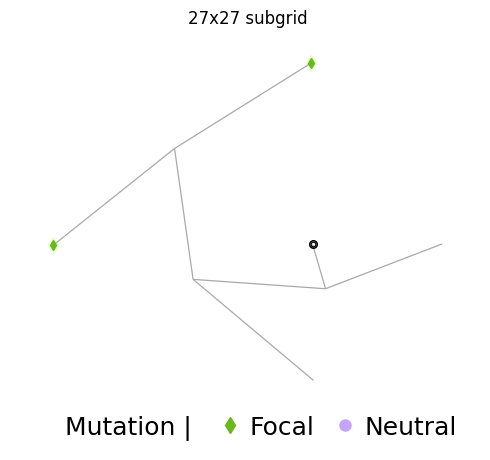

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=81x81+root_id=1493966+viz=tree+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=81x81+root_id=1493966+viz=tree+ext=.png


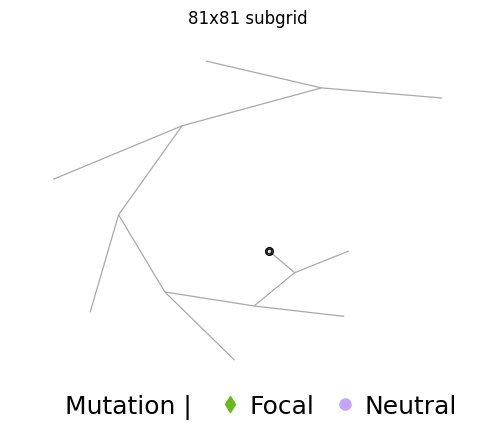

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=243x243+root_id=2002988+viz=tree+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=243x243+root_id=2002988+viz=tree+ext=.png


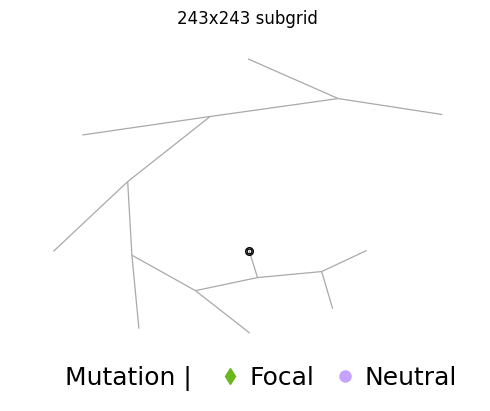

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=1170x755+root_id=27268+viz=tree+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=1170x755+root_id=27268+viz=tree+ext=.png


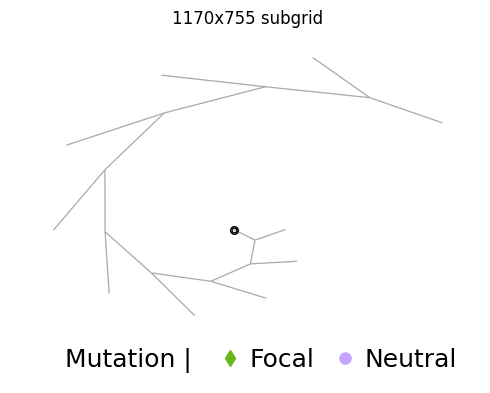

In [ ]:
_focal_mask = np.uint64(sum(1 << site for site in focal_sites))
_trait_present = phylo["trait_present"].to_numpy(dtype=np.uint64)
_is_leaf = phylo["is_leaf"].to_numpy()
_phylo = phylo.assign(
    has_mls=np.where(
        _is_leaf, (_trait_present & _focal_mask) != 0, np.nan
    ),
    has_neutral=np.where(
        _is_leaf, (_trait_present & ~_focal_mask) != 0, np.nan
    ),
)
_roots = _phylo.loc[_phylo["is_root"], ["id", "num_leaves", "pop_code"]]
_roots = _roots[_roots["num_leaves"] <= MAX_TREE_LEAVES]
_rng = random.Random(SEED)
for _pop_size in pop_size_order:
    _pops = populations.loc[
        populations["is_full_size"]
        & (populations["pop_size"] == _pop_size)
        & populations["pop_code"].isin(_roots["pop_code"]),
        "pop_code",
    ].tolist()
    if not _pops:
        continue
    _pop_code = _rng.choice(_pops)
    _root_id = (
        _roots.loc[_roots["pop_code"] == _pop_code]
        .nlargest(1, "num_leaves")["id"]
        .item()
    )

    _subtree = (
        _phylo[_phylo["root_id"] == _root_id]
        .pipe(pfl.alifestd_assign_contiguous_ids)
        .pipe(pfl.alifestd_try_add_ancestor_list_col)
    )
    _tree = apc.alife_dataframe_to_dendropy_tree(
        _subtree,
        setattrs=["has_mls", "has_neutral"],
    )
    with hstrat_aux.RngStateContext(6):
        _tree.ladderize()
        _tree.reorder(key=lambda *args: max(random.random(), 0.89))

    with tp.teed(
        ipx.plotting.tree,
        _tree,
        aspect=0.7,
        edge_color="darkgray",
        edge_linewidth=0.9,
        ladderize=True,
        layout="radial",
        layout_angular=True,
        layout_start=0.25,
        margins=0,
        teeplot_outattrs={"pop_size": _pop_size, "root_id": _root_id},
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _teed:
        plt.gcf().set_size_inches(6, 6)

        for _n, (_x, _y) in _teed.get_layout().T.items():
            _x_, _y_ = _x * np.cos(_y), _x * np.sin(_y)
            if _n.has_mls == 1.0:
                plt.plot(
                    _x_,
                    _y_,
                    "d",
                    markersize=8,
                    color="#E2FFC4",
                    alpha=0.8,
                    zorder=0,
                )
                plt.plot(
                    _x_,
                    _y_,
                    "d",
                    markersize=5,
                    color="#6AB81C",
                    alpha=1,
                    zorder=2,
                )
            if _n.has_neutral == 1.0:
                plt.plot(
                    _x_,
                    _y_,
                    "o",
                    markersize=5,
                    color="#C5A3FF",
                    alpha=0.3,
                    zorder=1,
                )
                plt.plot(
                    _x_,
                    _y_,
                    "o",
                    markersize=2.5,
                    color="#C5A3FF",
                    alpha=1.0,
                    zorder=3,
                )
            if _n is _tree.seed_node:
                for _size in 3.5, 5.5:
                    plt.plot(
                        _x_,
                        _y_,
                        "o",
                        markersize=_size,
                        color="black",
                        alpha=1,
                        fillstyle="none",
                    )

        plt.gca().margins(x=0.02, y=0.02)
        plt.title(f"{_pop_size} subgrid")

        (_h0,) = plt.plot(
            [], [], "d", markersize=0, color="#FFFFFF", label="Mutation | "
        )
        (_h1,) = plt.plot(
            [], [], "d", markersize=8, color="#6AB81C", label="Focal"
        )
        (_h2,) = plt.plot(
            [], [], "o", markersize=8, color="#C5A3FF", label="Neutral"
        )
        plt.legend(
            handles=[_h0, _h1, _h2],
            loc="upper center",
            bbox_to_anchor=(0.48, 0.05),
            frameon=False,
            ncol=4,
            fontsize=18,
            columnspacing=0.2,
            handletextpad=-0.2,
        )
    plt.close("all")

## Screen Mutation-defined Clades

MDCs are identified for each of the 16 trait sites by Fitch maximum parsimony over leaf states (root state assumed absent), as in `2026-10-15-mls-strong-fossils`.
Because each population's trees share no nodes with other populations', one screen over the whole forest is equivalent to screening each population separately.

The screen uses phyloframe's `alifestd_screen_trait_defined_clades_fitch_asexual`, which requires phyloframe >= 0.12.2 to run in linear time at this data size.

MDC size is measured as `carriers`, the number of descendant fossil genomes carrying the mutation; `num_genomes` counts all descendant fossil genomes.
`carrier_frac` is the carrier fraction among descendant genomes, and `is_terminal` marks MDCs arising on a terminal branch to a single genome (MDC node is an uncollapsed leaf).
`clade_duration` spans from MDC origin to its latest descendant fossil.
`num_pes` counts the distinct processing elements (PEs) among the MDC's carrier genomes, a measure of its spatial spread.

In [ ]:
_work = phylo[["id", "ancestor_id"]].copy()
assert (_work["id"] == np.arange(len(_work))).all()
_is_leaf = phylo["is_leaf"].to_numpy()
_clade_size = phylo["clade_size"].fillna(0).to_numpy(dtype=np.int64)
_trait_present = phylo["trait_present"].to_numpy(dtype=np.uint64)
_pe = phylo["pe"].fillna(-1).to_numpy(dtype=np.int64)
assert (_pe[_is_leaf] >= 0).all()
# each clade's nodes form a contiguous block in preorder, starting at the
# clade root and spanning its descendants
_preorder_pos = np.empty(len(_work), dtype=np.int64)
_preorder_pos[pfl.alifestd_unfurl_traversal_preorder_asexual(_work)] = (
    np.arange(len(_work))
)
_num_descendants = pfl.alifestd_mark_num_descendants_asexual(_work)[
    "num_descendants"
].to_numpy()
mdc_ids = {}
mdc_carriers = {}
mdc_num_pes = {}
for _site in mo.status.progress_bar(range(NUM_SITES)):
    _has = ((_trait_present >> np.uint64(_site)) & np.uint64(1)) != 0
    _mask = _work.pipe(
        pfl.alifestd_screen_trait_defined_clades_fitch_asexual,
        mutate=True,
        mask_trait_absent=_is_leaf & ~_has,
        mask_trait_present=_is_leaf & _has,
    ).astype(bool)
    # passing counts rather than a mask sums carriers over descendants
    _carriers = _work.pipe(
        pfl.alifestd_calc_clade_trait_count_asexual,
        mutate=True,
        trait_mask=np.where(_is_leaf & _has, _clade_size, 0),
    )
    _ids = np.flatnonzero(_mask)
    mdc_ids[_site] = _ids
    mdc_carriers[_site] = _carriers[_mask]
    # count distinct PEs among each MDC's carrier tips, by pairing each
    # MDC with the carrier tips in its preorder block
    _tips = np.flatnonzero(_is_leaf & _has)
    _order = np.argsort(_preorder_pos[_tips])
    _tip_pos = _preorder_pos[_tips][_order]
    _tip_pe = _pe[_tips][_order]
    _lo = np.searchsorted(_tip_pos, _preorder_pos[_ids])
    _hi = np.searchsorted(
        _tip_pos, _preorder_pos[_ids] + _num_descendants[_ids], "right"
    )
    _counts = _hi - _lo
    _mdc_idx = np.repeat(np.arange(len(_ids)), _counts)
    _tip_idx = np.repeat(_lo - np.cumsum(_counts) + _counts, _counts)
    _tip_idx += np.arange(len(_tip_idx))
    _pairs = np.unique(
        np.stack([_mdc_idx, _tip_pe[_tip_idx]], axis=1), axis=0
    )
    mdc_num_pes[_site] = np.bincount(_pairs[:, 0], minlength=len(_ids))

In [ ]:
_cols = [
    "id",
    "origin_time",
    "num_genomes",
    "clade_duration",
    "is_leaf",
    "clade_size",
    "pop_code",
]
mdcs = pd.concat(
    [
        phylo.loc[ids, _cols].assign(
            site=site,
            is_focal=site in focal_sites,
            is_control=site in control_sites,
            carriers=mdc_carriers[site],
            num_pes=mdc_num_pes[site],
        )
        for site, ids in mdc_ids.items()
    ],
    ignore_index=True,
)
mdcs["is_terminal"] = mdcs["is_leaf"] & (mdcs["clade_size"] == 1)
mdcs["carrier_frac"] = mdcs["carriers"] / mdcs["num_genomes"]
mdcs["mutation"] = mdcs["site"].map(site_labels)
mdcs = mdcs.drop(columns=["is_leaf", "clade_size"]).merge(
    populations[["pop_code", "pop_size", "pop_tiles"]], on="pop_code"
)
mdcs.groupby(["pop_size", "mutation"], sort=False).agg(
    num_mdcs=("id", "size"),
    carriers_mean=("carriers", "mean"),
    carriers_singleton_frac=("carriers", lambda x: (x == 1).mean()),
    carrier_frac_mean=("carrier_frac", "mean"),
    terminal_frac=("is_terminal", "mean"),
    clade_duration_mean=("clade_duration", "mean"),
    num_pes_mean=("num_pes", "mean"),
).unstack("pop_size")

num_mdcs carriers_mean carriers_singleton_frac ... terminal_frac clade_duration_mean num_pes_mean pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 ... 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 mutation BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.05 1374 1009 989 1028 1.963610 2.051536 2.137513 2.126459 0.545124 0.514371 ... 0.484328 0.494163 193.251092 195.929633 211.991911 206.405642 1.036390 1.033697 1.026289 1.027237 BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.025 686 505 500 532 1.838192 1.807921 1.888000 1.857143 0.591837 0.603960 ... 0.572000 0.582707 172.518950 162.857426 183.396000 173.503759 1.024781 1.021782 1.022000 1.016917 BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.01 321 276 245 260 1.514019 1.384058 1.502041 1.446154 0.719626 0.782609 ... 0.697959 0.734615 116.233645 84.344203 114.632653 97.526923 1.015576 1.010870 1.016327 1.015385 BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.005 237 205 182 209 1.417722 1.395122 1.472527 1.282297 0.772152 0.800000 ... 0.774725 0.808612 97.253165 90.775610 101.532967 72.942584 1.008439 1.009756 1.010989 1.004785 NEU$|^{\varnothing}_{\varnothing}$ 657 535 544 572 1.246575 1.175701 1.200368 1.243007 0.853881 0.871028 ... 0.867647 0.860140 64.948250 44.059813 52.255515 65.444056 1.019787 1.001869 1.014706 1.006993 ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... MLS$|^{-}_{+}$ s=0.005 233 194 181 217 1.377682 1.329897 1.370166 1.474654 0.789700 0.778351 ... 0.767956 0.783410 86.274678 79.175258 86.966851 99.405530 1.004292 1.000000 1.011050 1.023041 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.05 171 141 134 128 1.157895 1.141844 1.283582 1.265625 0.894737 0.893617 ... 0.828358 0.835938 50.239766 43.226950 72.231343 63.476562 1.000000 1.000000 1.014925 1.023438 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.025 157 134 129 145 1.152866 1.216418 1.263566 1.213793 0.872611 0.858209 ... 0.829457 0.855172 46.019108 49.850746 65.271318 53.131034 1.006369 1.000000 1.007752 1.020690 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.01 168 140 107 150 1.261905 1.150000 1.317757 1.286667 0.851190 0.907143 ... 0.822430 0.813333 65.041667 34.642857 77.233645 80.820000 1.005952 1.007143 1.009346 1.020000 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.005 154 132 154 131 1.363636 1.234848 1.207792 1.122137 0.798701 0.833333 ... 0.850649 0.900763 95.727273 76.378788 57.337662 31.786260 1.006494 1.007576 1.019481 1.007634 13 rows × 28 columns

## Mutation-frequency Screen

Within each population, baseline rate $\lambda$ is the mean MDC count per background (neutral) site.
Site significance is the Poisson survival probability of observing at least the site's MDC count under $\mathsf{Pois}(\lambda)$.
Neutral control sites are screened the same way, against the mean over the other background sites.
Populations with no background MDCs ($\lambda = 0$) are not screened.

In [ ]:
_pops = populations.loc[populations["is_full_size"], "pop_code"]
_counts = (
    mdcs.groupby(["pop_code", "site"])
    .size()
    .unstack("site")
    .reindex(index=_pops, columns=range(NUM_SITES))
    .fillna(0)
)
_bg_sum = _counts[background_sites].sum(axis=1)
_num_bg = len(background_sites)
_records = []
for _site in [*focal_sites, *control_sites]:
    _is_control = _site in control_sites
    _lam = (
        (_bg_sum - _counts[_site]) / (_num_bg - 1)
        if _is_control
        else _bg_sum / _num_bg
    )
    _k = _counts[_site]
    _records.append(
        pd.DataFrame(
            {
                "pop_code": _counts.index,
                "site": _site,
                "is_control": _is_control,
                "mdc_count": _k.to_numpy(),
                "lambda": _lam.to_numpy(),
                "fold_enrichment": (_k / _lam).to_numpy(),
                "poisson_sf_p": np.where(
                    _lam > 0, scipy_stats.poisson.sf(_k - 1, _lam), np.nan
                ),
            },
        ),
    )
freq_screen = pd.concat(_records, ignore_index=True).merge(
    populations[["pop_code", "pop_size", "pop_tiles"]], on="pop_code"
)
freq_screen["mutation"] = freq_screen["site"].map(site_labels)
freq_screen["detected"] = freq_screen["poisson_sf_p"] < ALPHA
freq_screen.groupby(["pop_size", "mutation"], sort=False).agg(
    num_populations=("pop_code", "nunique"),
    mdc_count_mean=("mdc_count", "mean"),
    lambda_mean=("lambda", "mean"),
    fold_enrichment_median=("fold_enrichment", "median"),
    detection_rate=("detected", "mean"),
).unstack("pop_size")

num_populations mdc_count_mean lambda_mean fold_enrichment_median detection_rate pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 mutation BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.05 1 1232 150 20 1374.00 0.818994 6.593333 51.40 164.25 0.108563 0.906667 7.15 8.365297 inf 8.000000 6.788306 1.00 0.055195 0.846667 0.9500 BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.025 1 1232 150 20 686.00 0.409903 3.333333 26.60 164.25 0.108563 0.906667 7.15 4.176560 4.0 3.266667 3.644289 1.00 0.024351 0.486667 0.8500 BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.01 1 1232 150 20 321.00 0.224026 1.633333 13.00 164.25 0.108563 0.906667 7.15 1.954338 0.0 2.000000 1.461905 1.00 0.004870 0.160000 0.4000 BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.005 1 1232 150 20 237.00 0.166396 1.213333 10.45 164.25 0.108563 0.906667 7.15 1.442922 0.0 1.333333 1.369369 1.00 0.003247 0.080000 0.2000 MLS$|^{-}_{+}$ s=0.05 1 1232 150 20 1409.00 0.914773 6.566667 53.60 164.25 0.108563 0.906667 7.15 8.578387 inf 8.000000 7.950000 1.00 0.064935 0.813333 0.9500 ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.05 1 1232 150 20 171.00 0.114448 0.893333 6.40 164.25 0.108563 0.906667 7.15 1.041096 0.0 0.800000 0.644444 0.00 0.003247 0.060000 0.1000 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.025 1 1232 150 20 157.00 0.108766 0.860000 7.25 164.25 0.108563 0.906667 7.15 0.955860 0.0 0.666667 1.005018 0.00 0.001623 0.033333 0.0500 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.01 1 1232 150 20 168.00 0.113636 0.713333 7.50 164.25 0.108563 0.906667 7.15 1.022831 0.0 0.571429 0.882432 0.00 0.000812 0.020000 0.1000 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.005 1 1232 150 20 154.00 0.107143 1.026667 6.55 164.25 0.108563 0.906667 7.15 0.937595 0.0 1.000000 0.926389 0.00 0.001623 0.080000 0.0000 NEU$|^{\varnothing}_{\varnothing}$ 1 1232 150 20 164.25 0.108563 0.906667 7.15 164.25 0.108563 0.906667 7.15 0.982403 0.0 0.750000 1.000000 0.25 0.001218 0.070000 0.0875 13 rows × 20 columns

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/estimator=median+hue=pop-size+viz=pointplot+x=mutation+y=fold-enrichment+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/estimator=median+hue=pop-size+viz=pointplot+x=mutation+y=fold-enrichment+ext=.png


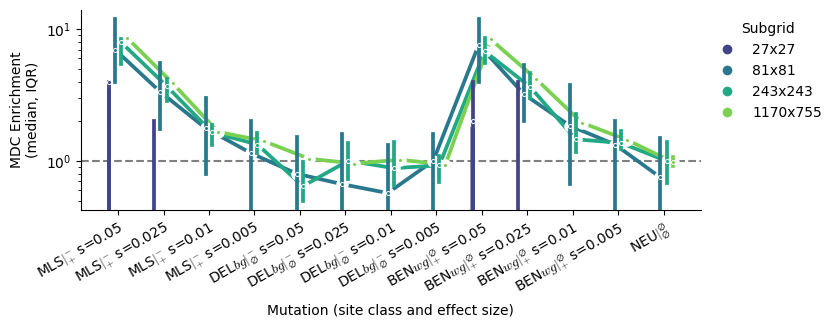

In [ ]:
with tp.teed(
    sns.pointplot,
    data=freq_screen.replace([np.inf, -np.inf], np.nan),
    x="mutation",
    y="fold_enrichment",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    estimator="median",
    errorbar=("pi", 50),
    dodge=0.4,
    teeplot_outexclude=["palette", "hue_order", "dodge", "order"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _ax:
    gap_points(_ax, _ax.get_legend())
    _ax.axhline(1, color="gray", linestyle="--", zorder=0)
    _ax.set_yscale("log")
    _ax.set_xlabel("Mutation (site class and effect size)")
    _ax.set_ylabel("MDC Enrichment\n(median, IQR)")
    plt.setp(
        _ax.get_xticklabels(),
        rotation=30,
        ha="right",
        rotation_mode="anchor",
    )
    sns.move_legend(
        _ax,
        "upper left",
        bbox_to_anchor=(1, 1),
        title="Subgrid",
        frameon=False,
    )
    sns.despine(ax=_ax)
    _ax.figure.set_size_inches(8, 2.6)

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/hue=pop-size+viz=pointplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/hue=pop-size+viz=pointplot+x=mutation+y=detected+ext=.png


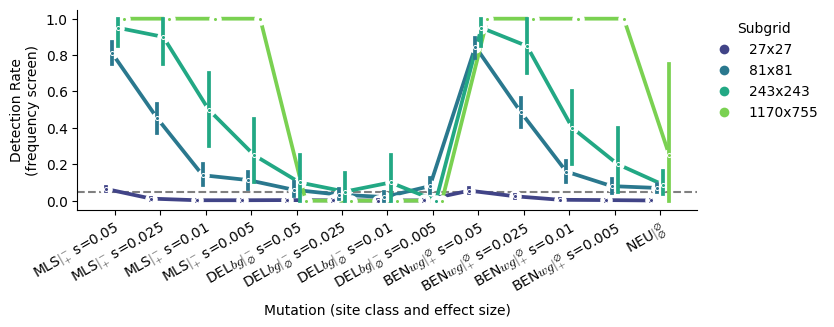

In [ ]:
with tp.teed(
    sns.pointplot,
    data=freq_screen.astype({"detected": float}),
    x="mutation",
    y="detected",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    errorbar=("ci", 95),
    n_boot=1000,
    seed=SEED,
    dodge=0.4,
    teeplot_outexclude=["palette", "hue_order", "dodge", "order", "seed"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _ax:
    gap_points(_ax, _ax.get_legend())
    _ax.axhline(ALPHA, color="gray", linestyle="--", zorder=0)
    _ax.set_ylim(-0.05, 1.05)
    _ax.set_xlabel("Mutation (site class and effect size)")
    _ax.set_ylabel("Detection Rate\n(frequency screen)")
    plt.setp(
        _ax.get_xticklabels(),
        rotation=30,
        ha="right",
        rotation_mode="anchor",
    )
    sns.move_legend(
        _ax,
        "upper left",
        bbox_to_anchor=(1, 1),
        title="Subgrid",
        frameon=False,
    )
    sns.despine(ax=_ax)
    _ax.figure.set_size_inches(8, 2.6)

## Clade-fitness Screen

Within each population, each MDC's size (`carriers`), clade duration, and PE count (`num_pes`) are percentile-ranked (mean rank for ties) against comparator MDCs: the pooled MDCs of background (neutral) sites in the same population, drawn from the same MDC subset.
Under the `epoch100` normalization, comparison is further restricted to comparators originating within the same 100-update `origin_time` bin, controlling for recency bias.

For each population and site, a one-sided Mann-Whitney U test asks whether the site's MDC percentiles are lower than those of background MDCs (excluding the site itself, for neutral control sites).
MLS predicts lower percentiles.

MDC subsets are `all` MDCs, `inner` (excluding terminal-branch MDCs), and `inner_f75` (non-terminal MDCs with at least 75% carriers).

In [ ]:
subsets = {
    "all": lambda df: np.ones(len(df), dtype=bool),
    "inner": lambda df: ~df["is_terminal"].to_numpy(),
    "inner_f75": lambda df: (
        ~df["is_terminal"].to_numpy()
        & (df["carrier_frac"].to_numpy() >= 0.75)
    ),
}

In [ ]:
normalizations = {"all": None, "epoch100": 100}
stat_cols = ("carriers", "clade_duration", "num_pes")
_parts = []
for _subset, _subset_mask in subsets.items():
    _data = mdcs[_subset_mask(mdcs)]
    _comparator = ~_data["is_focal"].to_numpy()
    _keep = ~_comparator | _data["is_control"].to_numpy()
    for _norm, _binwidth in normalizations.items():
        _epoch = (
            np.zeros(len(_data), dtype=np.int64)
            if _binwidth is None
            else (_data["origin_time"].to_numpy() // _binwidth).astype(
                np.int64
            )
        )
        _groups = _data["pop_code"].to_numpy() * 2**16 + _epoch
        for _stat in stat_cols:
            _parts.append(
                _data[
                    ["pop_code", "site", "is_focal", "is_control"]
                ].assign(
                    subset=_subset,
                    normalization=_norm,
                    stat=_stat,
                    percentile=percentileofscore_grouped(
                        _data[_stat].to_numpy(dtype=float),
                        _groups,
                        _comparator,
                    ),
                ),
            )
normed = pd.concat(_parts, ignore_index=True).dropna(subset=["percentile"])

In [ ]:
_records = []
_tested_sites = [*focal_sites, *control_sites]
for (_pop, _subset, _norm, _stat), _group in mo.status.progress_bar(
    normed.groupby(
        ["pop_code", "subset", "normalization", "stat"], sort=False
    ),
):
    _sites = _group["site"].to_numpy()
    _pct = _group["percentile"].to_numpy()
    _is_bg = ~_group["is_focal"].to_numpy()
    for _site in _tested_sites:
        _in_site = _sites == _site
        _x = _pct[_in_site]
        _y = _pct[_is_bg & ~_in_site]
        if not len(_x) or not len(_y):
            continue
        _mw_u, _mw_p = scipy_stats.mannwhitneyu(_x, _y, alternative="less")
        _records.append(
            {
                "pop_code": _pop,
                "subset": _subset,
                "normalization": _norm,
                "stat": _stat,
                "site": _site,
                "n_site": len(_x),
                "n_background": len(_y),
                "site_mean_pct": _x.mean(),
                "p_mw_less": _mw_p,
                "cliffs_delta": 2 * _mw_u / (len(_x) * len(_y)) - 1,
            },
        )
fitness_screen = pd.DataFrame(_records)

In [ ]:
# one row per screened (population, site), including those with no MDCs
# in subset, which count as not detected
_pop_sites = freq_screen[["pop_code", "site", "mutation"]]
fitness_detection = (
    fitness_screen[["subset", "normalization", "stat"]]
    .drop_duplicates()
    .merge(_pop_sites, how="cross")
    .merge(
        fitness_screen,
        on=["pop_code", "site", "subset", "normalization", "stat"],
        how="left",
    )
    .merge(populations[["pop_code", "pop_size", "pop_tiles"]])
)
fitness_detection["is_control"] = fitness_detection["site"].isin(
    control_sites
)
fitness_detection["detected"] = fitness_detection["p_mw_less"] < ALPHA
fitness_detection.groupby(
    ["subset", "normalization", "stat", "pop_size", "mutation"],
    sort=False,
).agg(
    num_populations=("pop_code", "nunique"),
    num_screened=("p_mw_less", "count"),
    n_site_mean=("n_site", "mean"),
    site_mean_pct_mean=("site_mean_pct", "mean"),
    cliffs_delta_mean=("cliffs_delta", "mean"),
    detection_rate=("detected", "mean"),
).unstack(
    "pop_size"
)

num_populations num_screened n_site_mean ... site_mean_pct_mean cliffs_delta_mean detection_rate pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 ... 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 subset normalization stat mutation all all carriers BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.05 1 1232 150 20 1 242 140 20 1374.0 1.438017 ... 71.172059 69.143885 0.319447 0.343836 0.423441 0.382878 0.0 0.0 0.0 0.0000 BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.025 1 1232 150 20 1 157 128 20 686.0 1.292994 ... 63.999439 63.515069 0.270951 0.304034 0.279989 0.270301 0.0 0.0 0.0 0.0000 BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.01 1 1232 150 20 1 79 114 20 321.0 1.113924 ... 57.847740 57.615884 0.136612 0.103376 0.156955 0.152318 0.0 0.0 0.0 0.0000 BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.005 1 1232 150 20 1 78 101 18 237.0 1.051282 ... 55.868158 54.936644 0.081389 0.167735 0.117363 0.098733 0.0 0.0 0.0 0.0500 MLS$|^{-}_{+}$ s=0.05 1 1232 150 20 1 265 139 20 1409.0 1.452830 ... 68.693882 69.941432 0.330828 0.435535 0.373878 0.398829 0.0 0.0 0.0 0.0000 ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... inner_f75 epoch100 num_pes DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.05 1 1232 150 20 1 0 2 7 17.0 NaN ... 50.000000 39.285714 -0.293505 NaN 0.000000 -0.214286 1.0 0.0 0.0 0.0500 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.025 1 1232 150 20 1 1 2 7 17.0 1.000000 ... 75.000000 42.857143 -0.292279 0.000000 0.500000 -0.142857 1.0 0.0 0.0 0.0000 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.01 1 1232 150 20 1 0 2 7 25.0 NaN ... 50.000000 53.571429 -0.012083 NaN 0.000000 0.089286 0.0 0.0 0.0 0.0000 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.005 1 1232 150 20 1 0 1 4 30.0 NaN ... 50.000000 37.500000 -0.187847 NaN 0.000000 -0.250000 0.0 0.0 0.0 0.0000 NEU$|^{\varnothing}_{\varnothing}$ 1 1232 150 20 4 6 21 43 24.0 1.000000 ... 50.000000 49.870801 -0.009261 0.000000 0.000000 -0.002104 0.0 0.0 0.0 0.0125 234 rows × 24 columns

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=stat+estimator=median+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=site-mean-pct+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=stat+estimator=median+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=site-mean-pct+ext=.png


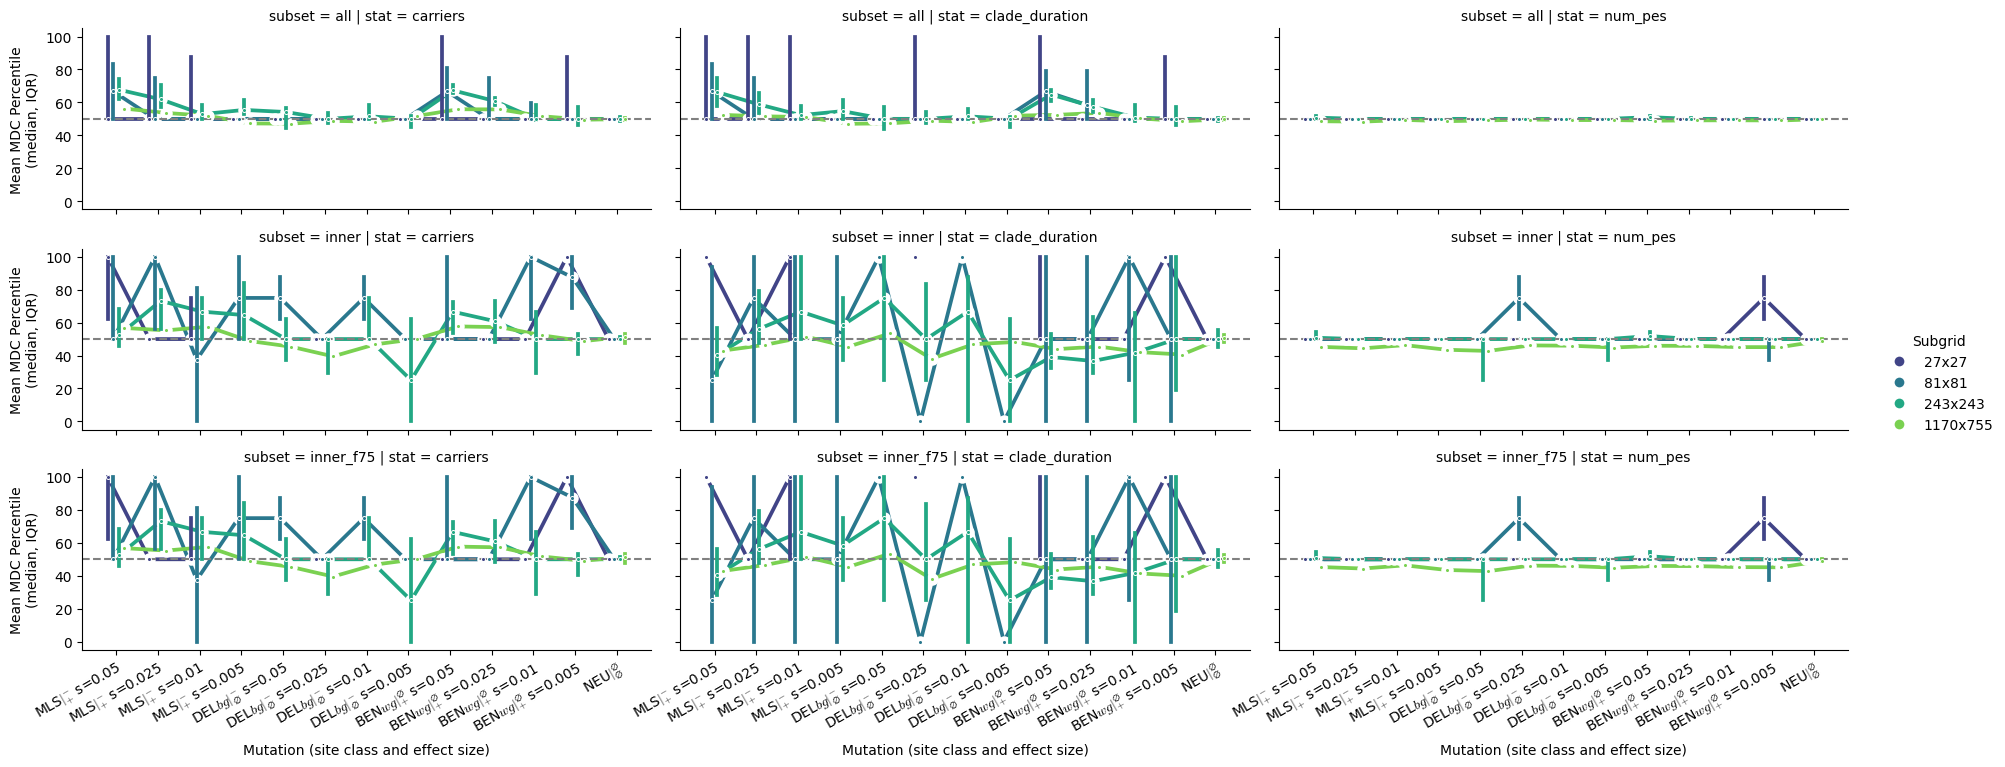

In [ ]:
with tp.teed(
    sns.catplot,
    data=fitness_detection[
        fitness_detection["normalization"] == "epoch100"
    ].dropna(subset=["site_mean_pct"]),
    x="mutation",
    y="site_mean_pct",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    col="stat",
    row="subset",
    kind="point",
    estimator="median",
    errorbar=("pi", 50),
    dodge=0.4,
    height=2.4,
    aspect=2.6,
    teeplot_outattrs={"normalization": "epoch100"},
    teeplot_outexclude=["palette", "hue_order", "dodge", "order"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    gap_points(*_g.axes.flat, _g.legend)
    _g.refline(y=50, color="gray", linestyle="--")
    _g.set_axis_labels(
        "Mutation (site class and effect size)",
        "Mean MDC Percentile\n(median, IQR)",
    )
    for _a in _g.axes.flat:
        plt.setp(
            _a.get_xticklabels(),
            rotation=30,
            ha="right",
            rotation_mode="anchor",
        )
    _g.legend.set_title("Subgrid")

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=stat+hue=pop-size+kind=point+normalization=all+row=subset+viz=catplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=stat+hue=pop-size+kind=point+normalization=all+row=subset+viz=catplot+x=mutation+y=detected+ext=.png


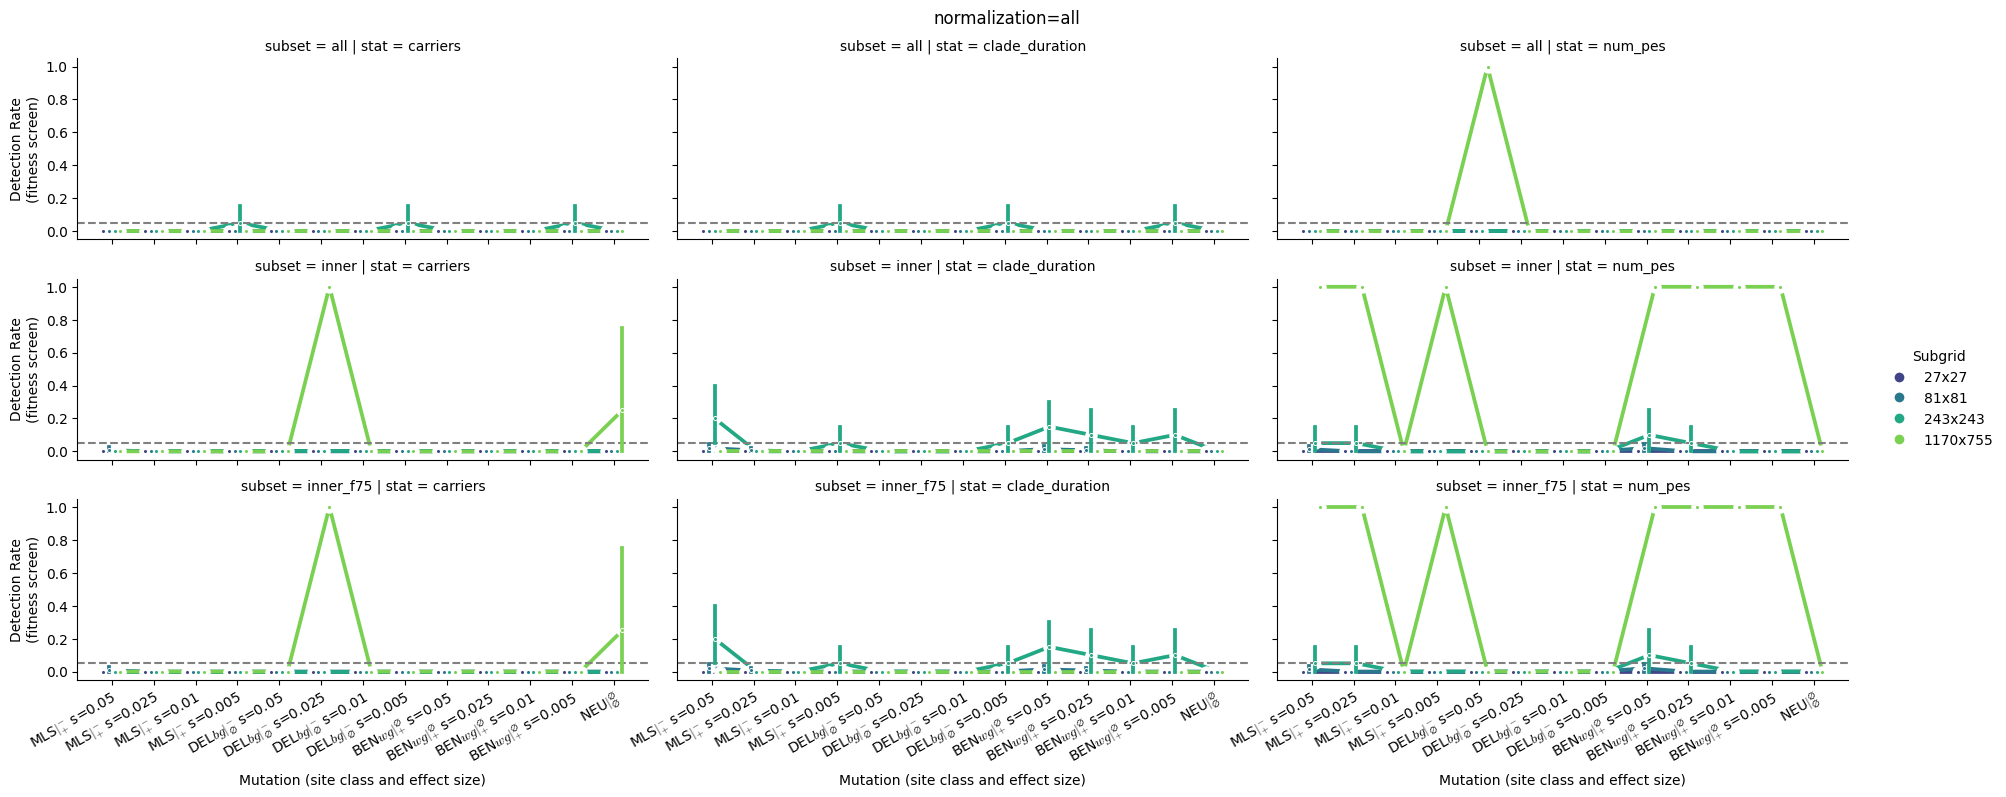

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=stat+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=stat+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=detected+ext=.png


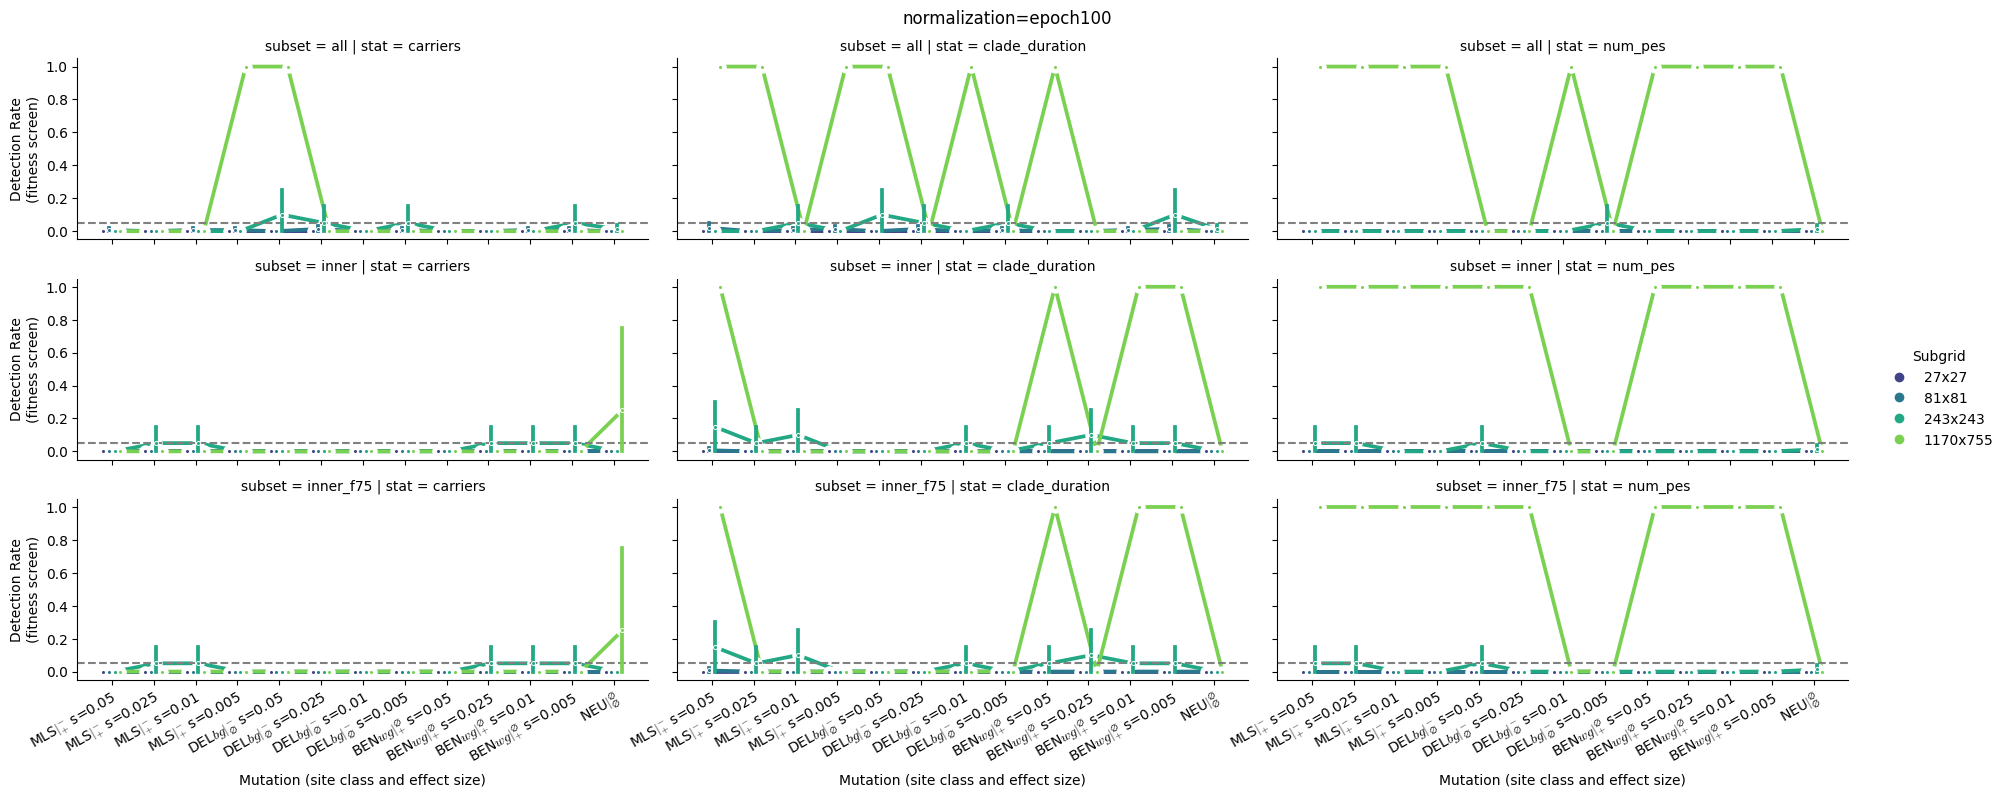

In [ ]:
for _norm in "all", "epoch100":
    with tp.teed(
        sns.catplot,
        data=fitness_detection[
            fitness_detection["normalization"] == _norm
        ].astype({"detected": float}),
        x="mutation",
        y="detected",
        order=mutation_order,
        hue="pop_size",
        hue_order=pop_size_order,
        palette="viridis",
        col="stat",
        row="subset",
        kind="point",
        errorbar=("ci", 95),
        n_boot=1000,
        seed=SEED,
        dodge=0.4,
        height=2.4,
        aspect=2.6,
        teeplot_outattrs={"normalization": _norm},
        teeplot_outexclude=[
            "palette",
            "hue_order",
            "dodge",
            "order",
            "seed",
        ],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        gap_points(*_g.axes.flat, _g.legend)
        _g.refline(y=ALPHA, color="gray", linestyle="--")
        _g.set(ylim=(-0.05, 1.05))
        _g.set_axis_labels(
            "Mutation (site class and effect size)",
            "Detection Rate\n(fitness screen)",
        )
        for _a in _g.axes.flat:
            plt.setp(
                _a.get_xticklabels(),
                rotation=30,
                ha="right",
                rotation_mode="anchor",
            )
        _g.legend.set_title("Subgrid")
        _g.figure.suptitle(f"normalization={_norm}", y=1.02)
    plt.close("all")

In [ ]:
mo.md(f"""
## Detectability Summary

Fraction of populations in which each screen detects each site at $\\alpha = {ALPHA}$, by population size (rows) and site class and effect size (columns).
The `NEU` column gives the false positive rate over neutral control sites, and should sit near {ALPHA}.
Fitness screens shown use `epoch100` normalization.

Note that sampled fossil genomes per population grow with subgrid size (fossils were sampled with an equal budget per fossil layer and subgrid), so population size and sample size are confounded here.
The full grid is a single population, so its detection rates are each 0 or 1.
""")

## Detectability Summary

Fraction of populations in which each screen detects each site at $\alpha = 0.05$, by population size (rows) and site class and effect size (columns).
The `NEU` column gives the false positive rate over neutral control sites, and should sit near 0.05.
Fitness screens shown use `epoch100` normalization.

Note that sampled fossil genomes per population grow with subgrid size (fossils were sampled with an equal budget per fossil layer and subgrid), so population size and sample size are confounded here.
The full grid is a single population, so its detection rates are each 0 or 1.

In [ ]:
_screens = {
    "frequency": freq_screen,
    **{
        f"fitness {_stat} {_subset}": fitness_detection[
            (fitness_detection["normalization"] == "epoch100")
            & (fitness_detection["stat"] == _stat)
            & (fitness_detection["subset"] == _subset)
        ]
        for _stat in ("carriers", "clade_duration", "num_pes")
        for _subset in ("all", "inner_f75")
    },
}
detectability = pd.concat(
    [
        _df.groupby(["pop_size", "mutation"], as_index=False)
        .agg(
            detection_rate=("detected", "mean"),
            num_screened=("detected", "size"),
        )
        .assign(screen=_screen)
        for _screen, _df in _screens.items()
    ],
    ignore_index=True,
)
detectability.pivot_table(
    index=["screen", "pop_size"],
    columns="mutation",
    values="detection_rate",
    sort=False,
)

mutation BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.005 BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.01 BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.025 BEN$\mathit{wg}|^{\varnothing}_{+}$ s=0.05 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.005 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.01 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.025 DEL$\mathit{bg}|^{-}_{\varnothing}$ s=0.05 MLS$|^{-}_{+}$ s=0.005 MLS$|^{-}_{+}$ s=0.01 MLS$|^{-}_{+}$ s=0.025 MLS$|^{-}_{+}$ s=0.05 NEU$|^{\varnothing}_{\varnothing}$ screen pop_size frequency 1170x755 1.000000 1.00000 1.000000 1.000000 0.000000 0.000000 0.000000 0.000000 1.000000 1.000000 1.000000 1.000000 0.250000 243x243 0.200000 0.40000 0.850000 0.950000 0.000000 0.100000 0.050000 0.100000 0.250000 0.500000 0.900000 0.950000 0.087500 27x27 0.003247 0.00487 0.024351 0.055195 0.001623 0.000812 0.001623 0.003247 0.002435 0.002435 0.011364 0.064935 0.001218 81x81 0.080000 0.16000 0.486667 0.846667 0.080000 0.020000 0.033333 0.060000 0.113333 0.140000 0.453333 0.813333 0.070000 fitness carriers all 1170x755 0.000000 0.00000 0.000000 0.000000 0.000000 0.000000 0.000000 1.000000 1.000000 0.000000 0.000000 0.000000 0.000000 ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... fitness num_pes all 81x81 0.000000 0.00000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 fitness num_pes inner_f75 1170x755 1.000000 1.00000 1.000000 1.000000 0.000000 0.000000 1.000000 1.000000 1.000000 1.000000 1.000000 1.000000 0.000000 243x243 0.000000 0.00000 0.000000 0.000000 0.000000 0.000000 0.000000 0.050000 0.000000 0.000000 0.050000 0.050000 0.012500 27x27 0.000000 0.00000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 81x81 0.000000 0.00000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 28 rows × 13 columns

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=frequency+viz=heatmap+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=frequency+viz=heatmap+ext=.png


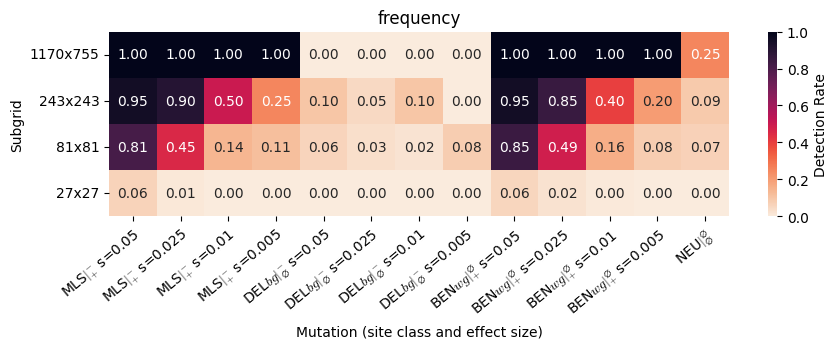

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=fitness-carriers-all+viz=heatmap+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=fitness-carriers-all+viz=heatmap+ext=.png


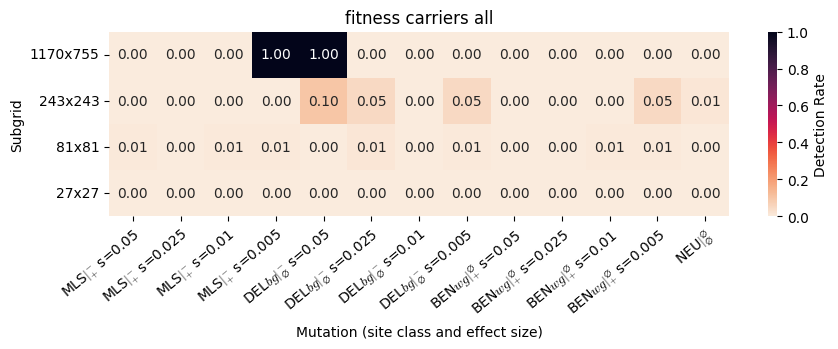

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=fitness-carriers-inner_f75+viz=heatmap+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=fitness-carriers-inner_f75+viz=heatmap+ext=.png


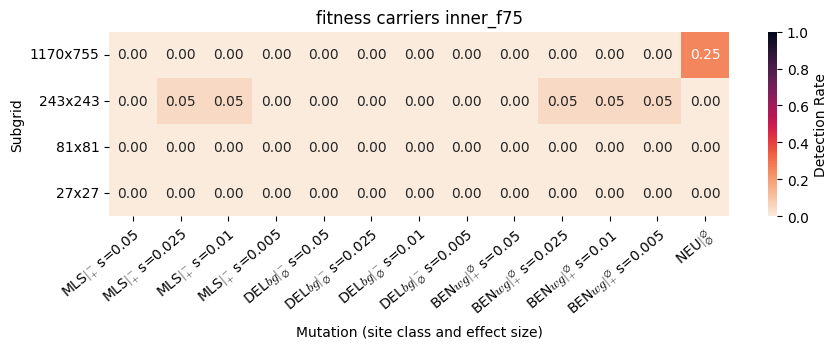

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=fitness-clade_duration-all+viz=heatmap+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=fitness-clade_duration-all+viz=heatmap+ext=.png


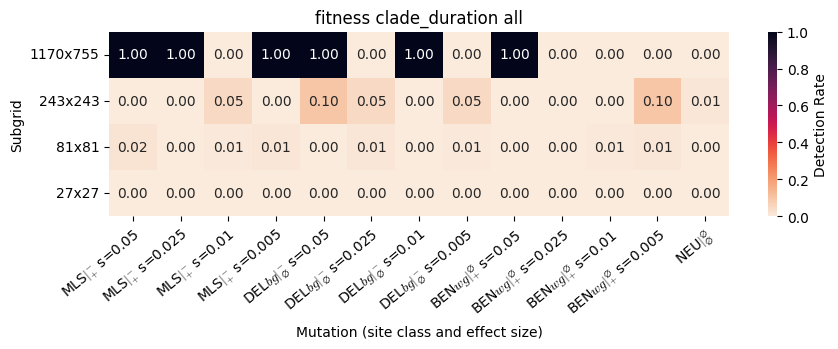

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=fitness-clade_duration-inner_f75+viz=heatmap+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=fitness-clade_duration-inner_f75+viz=heatmap+ext=.png


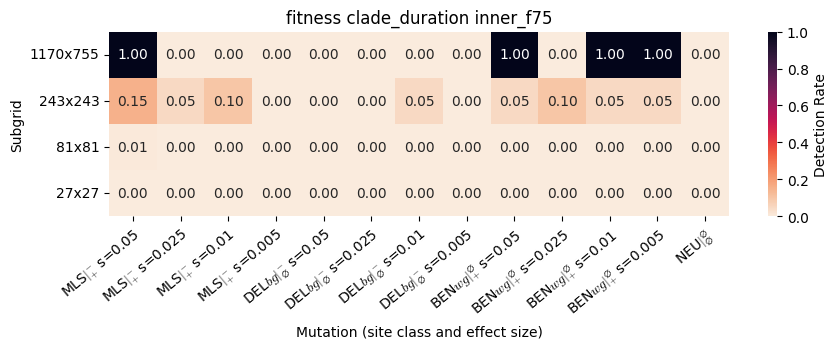

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=fitness-num_pes-all+viz=heatmap+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=fitness-num_pes-all+viz=heatmap+ext=.png


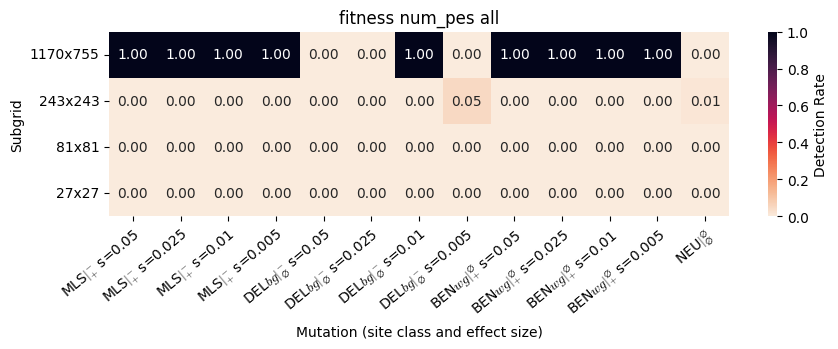

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=fitness-num_pes-inner_f75+viz=heatmap+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/screen=fitness-num_pes-inner_f75+viz=heatmap+ext=.png


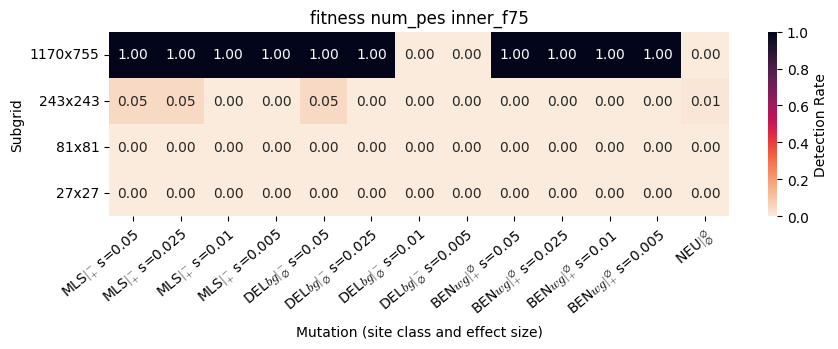

In [ ]:
for _screen, _df in detectability.groupby("screen", sort=False):
    _pivot = _df.pivot(
        index="pop_size", columns="mutation", values="detection_rate"
    ).reindex(index=pop_size_order[::-1], columns=mutation_order)
    with tp.teed(
        sns.heatmap,
        _pivot,
        annot=True,
        fmt=".2f",
        cmap="rocket_r",
        vmin=0,
        vmax=1,
        cbar_kws={"label": "Detection Rate"},
        teeplot_outattrs={"screen": _screen.replace(" ", "-")},
        teeplot_outexclude=["annot", "fmt", "cmap", "vmin", "vmax"],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _ax:
        _ax.set_xlabel("Mutation (site class and effect size)")
        _ax.set_ylabel("Subgrid")
        _ax.set_title(_screen)
        plt.setp(
            _ax.get_xticklabels(),
            rotation=40,
            ha="right",
            rotation_mode="anchor",
        )
        _ax.tick_params(axis="y", rotation=0)
        _ax.figure.set_size_inches(10, 2.4)
    plt.close("all")

In [ ]:
mo.md(f"""
## Detectability by Site Class

The same screen results, recast with effect size on the x axis, site class as color, and subgrid size as columns.
Neutral control sites appear as their own x position.
Error bars are 95% bootstrap confidence intervals over populations; the dashed line marks $\\alpha = {ALPHA}$.
Fitness screens shown use `epoch100` normalization.
""")

## Detectability by Site Class

The same screen results, recast with effect size on the x axis, site class as color, and subgrid size as columns.
Neutral control sites appear as their own x position.
Error bars are 95% bootstrap confidence intervals over populations; the dashed line marks $\alpha = 0.05$.
Fitness screens shown use `epoch100` normalization.

In [ ]:
def _split_mutation(df):
    _parts = df["mutation"].str.extract(r"^(.+) s=(\S+)$")
    return df.assign(
        kind=_parts[0].fillna(kind_labels["NEU"]),
        effect_size=_parts[1].fillna("neu").map(effect_pct),
    )

by_kind = pd.concat(
    [
        freq_screen.assign(
            screen="frequency", p_value=freq_screen["poisson_sf_p"]
        ),
        *(
            fitness_detection[
                (fitness_detection["normalization"] == "epoch100")
                & (fitness_detection["stat"] == _stat)
                & (fitness_detection["subset"] == _subset)
            ].assign(
                screen=f"fitness {_stat} {_subset}",
                p_value=lambda df: df["p_mw_less"],
            )
            for _stat in ("carriers", "clade_duration", "num_pes")
            for _subset in ("all", "inner_f75")
        ),
    ],
    ignore_index=True,
)[
    [
        "screen",
        "pop_code",
        "pop_size",
        "site",
        "mutation",
        "detected",
        "site_mean_pct",
        "p_value",
    ]
].pipe(
    _split_mutation
)
kind_order = [
    kind_labels[_kind]
    for _kind in ("NEU", "BENwg", "DELbg", "MLS")
    if kind_labels[_kind] in set(by_kind["kind"])
]
effect_size_order = ["neu"] + sorted(
    set(by_kind["effect_size"]) - {"neu"}, key=float
)
kind_palette = {
    kind_labels[_kind]: ETI_PALETTE[_key][1]
    for _kind, _key in (
        ("NEU", "neutral"),
        ("BENwg", "BENwg"),
        ("DELbg", "DELbg"),
        ("MLS", "MLS"),
    )
}
freq_by_kind = freq_screen.pipe(_split_mutation)
by_kind.groupby(["screen", "pop_size", "kind", "effect_size"], sort=False)[
    "detected"
].mean().unstack("pop_size")

pop_size 1170x755 27x27 81x81 243x243 screen kind effect_size frequency BEN$\mathit{wg}|^{\varnothing}_{+}$ 5.0 1.0 0.055195 0.846667 0.9500 2.5 1.0 0.024351 0.486667 0.8500 1.0 1.0 0.004870 0.160000 0.4000 0.5 1.0 0.003247 0.080000 0.2000 MLS$|^{-}_{+}$ 5.0 1.0 0.064935 0.813333 0.9500 ... ... ... ... ... ... ... fitness num_pes inner_f75 DEL$\mathit{bg}|^{-}_{\varnothing}$ 5.0 1.0 0.000000 0.000000 0.0500 2.5 1.0 0.000000 0.000000 0.0000 1.0 0.0 0.000000 0.000000 0.0000 0.5 0.0 0.000000 0.000000 0.0000 NEU$|^{\varnothing}_{\varnothing}$ neu 0.0 0.000000 0.000000 0.0125 91 rows × 4 columns

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=frequency+viz=catplot+x=effect-size+y=detected+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=frequency+viz=catplot+x=effect-size+y=detected+ext=.png


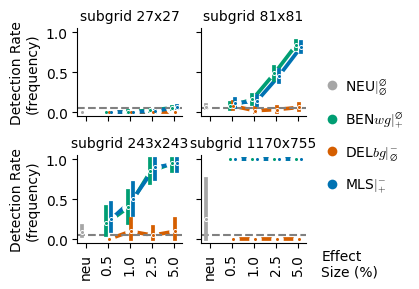

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-carriers-all+viz=catplot+x=effect-size+y=detected+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-carriers-all+viz=catplot+x=effect-size+y=detected+ext=.png


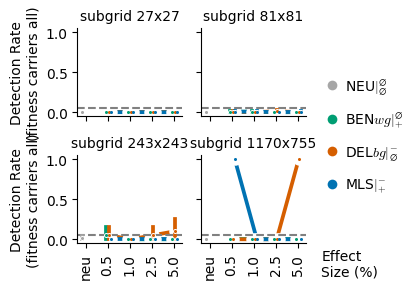

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-carriers-inner_f75+viz=catplot+x=effect-size+y=detected+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-carriers-inner_f75+viz=catplot+x=effect-size+y=detected+ext=.png


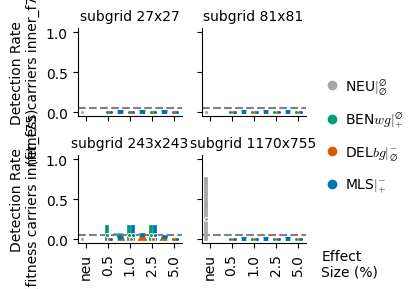

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-clade_duration-all+viz=catplot+x=effect-size+y=detected+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-clade_duration-all+viz=catplot+x=effect-size+y=detected+ext=.png


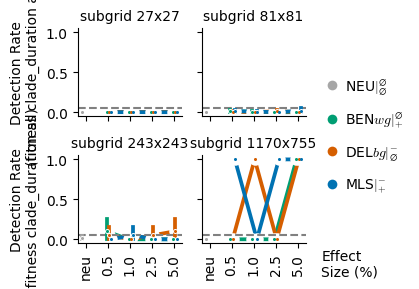

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-clade_duration-inner_f75+viz=catplot+x=effect-size+y=detected+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-clade_duration-inner_f75+viz=catplot+x=effect-size+y=detected+ext=.png


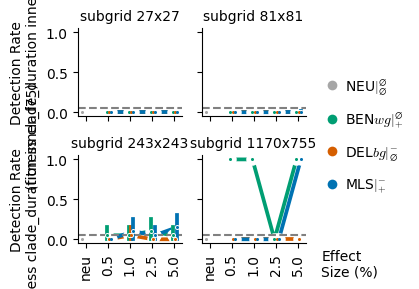

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-num_pes-all+viz=catplot+x=effect-size+y=detected+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-num_pes-all+viz=catplot+x=effect-size+y=detected+ext=.png


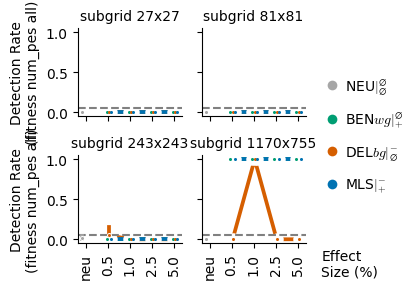

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-num_pes-inner_f75+viz=catplot+x=effect-size+y=detected+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-num_pes-inner_f75+viz=catplot+x=effect-size+y=detected+ext=.png


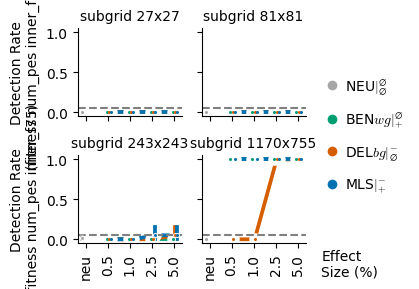

In [ ]:
for _screen, _df in by_kind.groupby("screen", sort=False):
    with tp.teed(
        sns.catplot,
        data=_df.astype({"detected": float}),
        x="effect_size",
        y="detected",
        order=effect_size_order,
        hue="kind",
        hue_order=kind_order,
        palette=kind_palette,
        col="pop_size",
        col_order=pop_size_order,
        col_wrap=2,
        kind="point",
        errorbar=("ci", 95),
        n_boot=1000,
        seed=SEED,
        dodge=0.3,
        height=1.5,
        aspect=1.1,
        teeplot_outattrs={"screen": _screen.replace(" ", "-")},
        teeplot_outexclude=[
            "palette",
            "hue_order",
            "col_order",
            "col_wrap",
            "dodge",
            "order",
            "seed",
        ],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        gap_points(*_g.axes.flat, _g.legend)
        _g.refline(y=ALPHA, color="gray", linestyle="--")
        _g.set(ylim=(-0.05, 1.05))
        _g.set_axis_labels("", f"Detection Rate\n({_screen})")
        _g.set_titles(col_template="subgrid {col_name}")
        for _a in _g.axes.flat:
            plt.setp(
                _a.get_xticklabels(),
                rotation=90,
                ha="right",
                va="center",
                rotation_mode="anchor",
            )
        corner_xlabel(_g, right_legend(_g))
    plt.close("all")

## MDC Size and Duration by Site Class

The fitness screen's underlying measurement: each site's mean MDC percentile for clade size (`carriers`) and clade duration, ranked against background (neutral) MDCs within the same population and 100-update origin epoch.
All MDCs are included.
The dashed line at 50 marks parity with background; lower values mean smaller or shorter-lived clades.
Points are medians over populations, with error bars spanning the interquartile range.

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-carriers-all+viz=catplot+x=effect-size+y=site-mean-pct+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-carriers-all+viz=catplot+x=effect-size+y=site-mean-pct+ext=.png


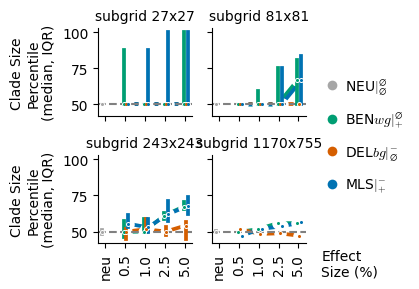

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-clade_duration-all+viz=catplot+x=effect-size+y=site-mean-pct+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-clade_duration-all+viz=catplot+x=effect-size+y=site-mean-pct+ext=.png


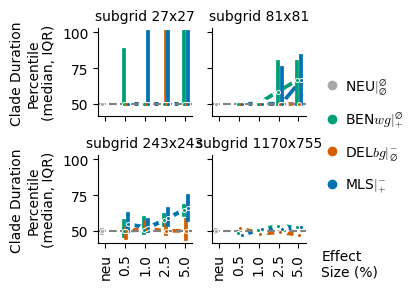

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-num_pes-all+viz=catplot+x=effect-size+y=site-mean-pct+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-num_pes-all+viz=catplot+x=effect-size+y=site-mean-pct+ext=.png


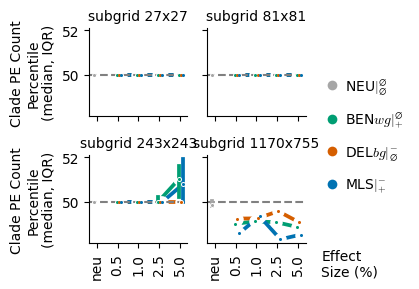

In [ ]:
_stat_names = {
    "carriers": "Clade Size",
    "clade_duration": "Clade Duration",
    "num_pes": "Clade PE Count",
}
# all MDCs subset only
_fitness = by_kind[
    by_kind["screen"].str.startswith("fitness ")
    & by_kind["screen"].str.endswith(" all")
]
for _screen, _df in _fitness.groupby("screen", sort=False):
    _stat = _screen.split(" ")[1]
    with tp.teed(
        sns.catplot,
        data=_df.dropna(subset=["site_mean_pct"]),
        x="effect_size",
        y="site_mean_pct",
        order=effect_size_order,
        hue="kind",
        hue_order=kind_order,
        palette=kind_palette,
        col="pop_size",
        col_order=pop_size_order,
        col_wrap=2,
        kind="point",
        estimator="median",
        errorbar=("pi", 50),
        dodge=0.3,
        height=1.5,
        aspect=1.1,
        teeplot_outattrs={"screen": _screen.replace(" ", "-")},
        teeplot_outexclude=[
            "palette",
            "hue_order",
            "col_order",
            "col_wrap",
            "dodge",
            "order",
        ],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        gap_points(*_g.axes.flat, _g.legend)
        _g.refline(y=50, color="gray", linestyle="--")
        _g.set_axis_labels(
            "",
            f"{_stat_names[_stat]}\nPercentile\n(median, IQR)",
        )
        _g.set_titles(col_template="subgrid {col_name}")
        for _a in _g.axes.flat:
            plt.setp(
                _a.get_xticklabels(),
                rotation=90,
                ha="right",
                va="center",
                rotation_mode="anchor",
            )
        corner_xlabel(_g, right_legend(_g))
    plt.close("all")

In [ ]:
mo.md(f"""
## Detection Strength by Site Class

Screen p-values on a log scale, descending from $p = 1$ at top so stronger evidence plots lower.
Points are medians over populations, with error bars spanning the interquartile range; the dashed line marks $\\alpha = {ALPHA}$.
Populations where a site produced no MDCs (so the screen could not run) count as $p = 1$, and p-values below $10^{{-9}}$ are clipped to $10^{{-9}}$.
Fitness screens shown use all MDCs and `epoch100` normalization.
""")

## Detection Strength by Site Class

Screen p-values on a log scale, descending from $p = 1$ at top so stronger evidence plots lower.
Points are medians over populations, with error bars spanning the interquartile range; the dashed line marks $\alpha = 0.05$.
Populations where a site produced no MDCs (so the screen could not run) count as $p = 1$, and p-values below $10^{-9}$ are clipped to $10^{-9}$.
Fitness screens shown use all MDCs and `epoch100` normalization.

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=frequency+viz=catplot+x=effect-size+y=p-value+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=frequency+viz=catplot+x=effect-size+y=p-value+ext=.png


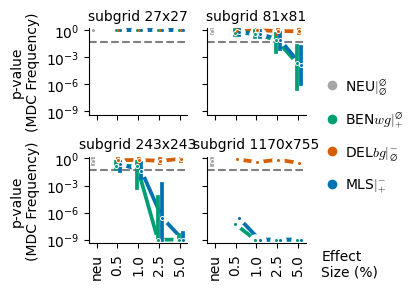

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-carriers-all+viz=catplot+x=effect-size+y=p-value+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-carriers-all+viz=catplot+x=effect-size+y=p-value+ext=.png


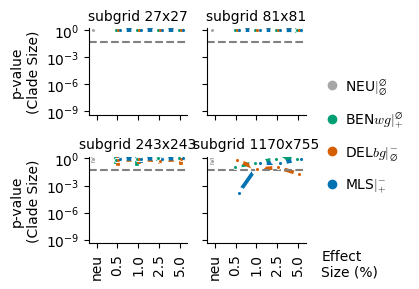

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-clade_duration-all+viz=catplot+x=effect-size+y=p-value+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-clade_duration-all+viz=catplot+x=effect-size+y=p-value+ext=.png


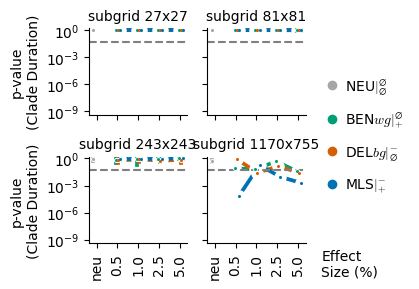

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-num_pes-all+viz=catplot+x=effect-size+y=p-value+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-num_pes-all+viz=catplot+x=effect-size+y=p-value+ext=.png


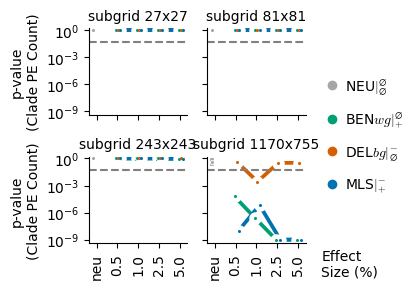

In [ ]:
_screen_names = {
    "frequency": "MDC Frequency",
    "fitness carriers all": "Clade Size",
    "fitness clade_duration all": "Clade Duration",
    "fitness num_pes all": "Clade PE Count",
}
for _screen, _name in _screen_names.items():
    _df = by_kind[by_kind["screen"] == _screen].assign(
        p_value=lambda df: df["p_value"].fillna(1.0).clip(lower=1e-9),
    )
    with tp.teed(
        sns.catplot,
        data=_df,
        x="effect_size",
        y="p_value",
        order=effect_size_order,
        hue="kind",
        hue_order=kind_order,
        palette=kind_palette,
        col="pop_size",
        col_order=pop_size_order,
        col_wrap=2,
        kind="point",
        estimator="median",
        errorbar=("pi", 50),
        dodge=0.3,
        height=1.5,
        aspect=1.1,
        log_scale=(False, True),
        teeplot_outattrs={"screen": _screen.replace(" ", "-")},
        teeplot_outexclude=[
            "palette",
            "hue_order",
            "col_order",
            "col_wrap",
            "dodge",
            "order",
            "log_scale",
        ],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        gap_points(*_g.axes.flat, _g.legend)
        _g.refline(y=ALPHA, color="gray", linestyle="--")
        # p = 1 at top, descending to the 1e-9 clip floor, with a
        # little padding so edge markers aren't cut off
        _g.set(
            ylim=(10**-9.4, 10**0.2),
            yticks=[1, 1e-3, 1e-6, 1e-9],
        )
        _g.set_axis_labels("", f"p-value\n({_name})")
        _g.set_titles(col_template="subgrid {col_name}")
        for _a in _g.axes.flat:
            plt.setp(
                _a.get_xticklabels(),
                rotation=90,
                ha="right",
                va="center",
                rotation_mode="anchor",
            )
        corner_xlabel(_g, right_legend(_g))
    plt.close("all")

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+viz=catplot+x=effect-size+y=fold-enrichment+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+viz=catplot+x=effect-size+y=fold-enrichment+ext=.png


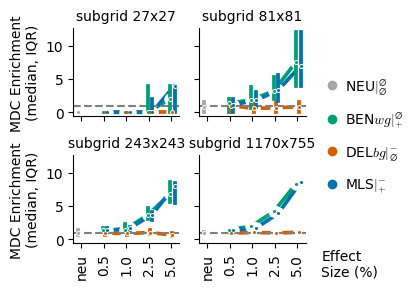

In [ ]:
with tp.teed(
    sns.catplot,
    data=freq_by_kind,
    x="effect_size",
    y="fold_enrichment",
    order=effect_size_order,
    hue="kind",
    hue_order=kind_order,
    palette=kind_palette,
    col="pop_size",
    col_order=pop_size_order,
    col_wrap=2,
    kind="point",
    estimator="median",
    errorbar=("pi", 50),
    dodge=0.3,
    height=1.5,
    aspect=1.1,
    teeplot_outexclude=[
        "palette",
        "hue_order",
        "col_order",
        "col_wrap",
        "dodge",
        "order",
    ],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    gap_points(*_g.axes.flat, _g.legend)
    _g.refline(y=1, color="gray", linestyle="--")
    _g.set_axis_labels("", "MDC Enrichment\n(median, IQR)")
    _g.set_titles(col_template="subgrid {col_name}")
    for _a in _g.axes.flat:
        plt.setp(
            _a.get_xticklabels(),
            rotation=90,
            ha="right",
            va="center",
            rotation_mode="anchor",
        )
    corner_xlabel(_g, right_legend(_g))
plt.close("all")

In [ ]:
mo.md(f"""
## Paired Mutation-frequency Screen: MLS vs. DELbg

MLS and between-group deleterious (`DELbg`) sites at the same effect size share the same transmission reduction, so any difference in their MDC counts comes from the MLS site's within-host advantage.
Within each population, for each effect size, this screen tests whether the MLS site gives rise to more MDCs than the `DELbg` site.
Under the null of equal rates, given $n = k_\\mathrm{{MLS}} + k_\\mathrm{{del}}$ MDCs in total, $k_\\mathrm{{MLS}} \\sim \\mathsf{{Binom}}(n, 1/2)$, so significance is the one-sided binomial survival probability of observing at least $k_\\mathrm{{MLS}}$ (the conditional exact test comparing two Poisson counts).
Populations with no MDCs at either site count as not detected.
As a null calibration, neutral sites are paired off and screened the same way.
Error bars are 95% bootstrap confidence intervals over populations; the dashed line marks $\\alpha = {ALPHA}$.
""")

## Paired Mutation-frequency Screen: MLS vs. DELbg

MLS and between-group deleterious (`DELbg`) sites at the same effect size share the same transmission reduction, so any difference in their MDC counts comes from the MLS site's within-host advantage.
Within each population, for each effect size, this screen tests whether the MLS site gives rise to more MDCs than the `DELbg` site.
Under the null of equal rates, given $n = k_\mathrm{MLS} + k_\mathrm{del}$ MDCs in total, $k_\mathrm{MLS} \sim \mathsf{Binom}(n, 1/2)$, so significance is the one-sided binomial survival probability of observing at least $k_\mathrm{MLS}$ (the conditional exact test comparing two Poisson counts).
Populations with no MDCs at either site count as not detected.
As a null calibration, neutral sites are paired off and screened the same way.
Error bars are 95% bootstrap confidence intervals over populations; the dashed line marks $\alpha = 0.05$.

In [ ]:
_counts = freq_screen.pivot(
    index="pop_code", columns="site", values="mdc_count"
)
_site_of = {label: site for site, label in site_labels.items()}
_pairs = [
    (
        label.split("=")[1],
        _site,
        _site_of[f"{kind_labels['DELbg']} s={label.split('=')[1]}"],
    )
    for _site, label in site_labels.items()
    if label.startswith(kind_labels["MLS"])
] + [
    ("neu", _a, _b)
    for _a, _b in zip(background_sites[::2], background_sites[1::2])
]
paired_freq_screen = pd.concat(
    [
        pd.DataFrame(
            {
                "pop_code": _counts.index,
                "effect_size": effect_pct(_effect),
                "kind": (
                    (
                        kind_labels["NEU"]
                        if _effect == "neu"
                        else kind_labels["MLS"]
                    )
                ),
                "site": _site,
                "comparator_site": _comparator,
                "k_site": _counts[_site].to_numpy(),
                "k_comparator": _counts[_comparator].to_numpy(),
            },
        )
        for _effect, _site, _comparator in _pairs
    ],
    ignore_index=True,
).merge(
    freq_screen[["pop_code", "pop_size"]].drop_duplicates(),
    on="pop_code",
)
_n = paired_freq_screen["k_site"] + paired_freq_screen["k_comparator"]
paired_freq_screen["binom_sf_p"] = np.where(
    _n > 0,
    scipy_stats.binom.sf(paired_freq_screen["k_site"] - 1, _n, 0.5),
    np.nan,
)
paired_freq_screen["detected"] = paired_freq_screen["binom_sf_p"] < ALPHA
paired_freq_screen.groupby(
    ["pop_size", "kind", "effect_size"], sort=False
).agg(
    num_populations=("pop_code", "nunique"),
    k_site_mean=("k_site", "mean"),
    k_comparator_mean=("k_comparator", "mean"),
    detection_rate=("detected", "mean"),
).unstack(
    "pop_size"
)

num_populations k_site_mean k_comparator_mean detection_rate pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 kind effect_size MLS$|^{-}_{+}$ 5.0 1 1232 150 20 1409.0 0.914773 6.566667 53.60 171.0 0.114448 0.893333 6.40 1.0 0.002435 0.546667 0.900 2.5 1 1232 150 20 640.0 0.395292 3.006667 25.65 157.0 0.108766 0.860000 7.25 1.0 0.000000 0.093333 0.750 1.0 1 1232 150 20 273.0 0.185065 1.706667 13.40 168.0 0.113636 0.713333 7.50 1.0 0.000000 0.026667 0.250 0.5 1 1232 150 20 233.0 0.157468 1.206667 10.85 154.0 0.107143 1.026667 6.55 1.0 0.000000 0.006667 0.150 NEU$|^{\varnothing}_{\varnothing}$ neu 1 1232 150 20 158.5 0.101867 0.943333 6.70 170.0 0.115260 0.870000 7.60 0.0 0.000000 0.000000 0.025

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=paired-frequency+viz=catplot+x=effect-size+y=detected+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=paired-frequency+viz=catplot+x=effect-size+y=detected+ext=.png


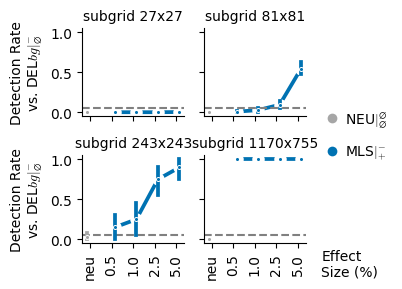

In [ ]:
with tp.teed(
    sns.catplot,
    data=paired_freq_screen.astype({"detected": float}),
    x="effect_size",
    y="detected",
    order=effect_size_order,
    hue="kind",
    hue_order=[kind_labels["NEU"], kind_labels["MLS"]],
    palette=kind_palette,
    col="pop_size",
    col_order=pop_size_order,
    col_wrap=2,
    kind="point",
    errorbar=("ci", 95),
    n_boot=1000,
    seed=SEED,
    dodge=0.3,
    height=1.5,
    aspect=1.1,
    teeplot_outattrs={"screen": "paired-frequency"},
    teeplot_outexclude=[
        "palette",
        "hue_order",
        "col_order",
        "col_wrap",
        "dodge",
        "order",
        "seed",
    ],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    gap_points(*_g.axes.flat, _g.legend)
    _g.refline(y=ALPHA, color="gray", linestyle="--")
    _g.set(ylim=(-0.05, 1.05))
    _g.set_axis_labels(
        "",
        f"Detection Rate\nvs. {kind_labels['DELbg']}",
    )
    _g.set_titles(col_template="subgrid {col_name}")
    for _a in _g.axes.flat:
        plt.setp(
            _a.get_xticklabels(),
            rotation=90,
            ha="right",
            va="center",
            rotation_mode="anchor",
        )
    corner_xlabel(_g, right_legend(_g))
plt.close("all")

MDC fold enrichment normalized to the between-group deleterious (`DELbg`) site at the same effect size (rather than to neutral sites), i.e., $k_\mathrm{site} / k_\mathrm{DELbg}$ within each population.
MLS sites above 1 reflect their within-host advantage over an otherwise-equal transmission cost.
As a null reference, neutral sites are paired off and normalized to each other.
Populations with no MDCs at the normalizing site are omitted.
Points give medians and error bars interquartile ranges over populations.

In [ ]:
_counts = freq_screen.pivot(
    index="pop_code", columns="site", values="mdc_count"
)
_site_of = {label: site for site, label in site_labels.items()}
_pairs = [
    (
        _kind,
        _effect,
        _site,
        _site_of[f"{kind_labels['DELbg']} s={_effect}"],
    )
    for _site, _label in site_labels.items()
    if _label.startswith((kind_labels["MLS"], kind_labels["BENwg"]))
    for _kind, _effect in [_label.split(" s=")]
] + [
    (kind_labels["NEU"], "neu", _a, _b)
    for _a, _b in zip(background_sites[::2], background_sites[1::2])
]
del_enrichment = pd.concat(
    [
        pd.DataFrame(
            {
                "pop_code": _counts.index,
                "kind": _kind,
                "effect_size": effect_pct(_effect),
                "site": _site,
                "k_site": _counts[_site].to_numpy(),
                "k_del": _counts[_norm].to_numpy(),
            },
        )
        for _kind, _effect, _site, _norm in _pairs
    ],
    ignore_index=True,
).merge(
    freq_screen[["pop_code", "pop_size"]].drop_duplicates(),
    on="pop_code",
)
del_enrichment = del_enrichment[del_enrichment["k_del"] > 0].copy()
del_enrichment["fold_enrichment_del"] = (
    del_enrichment["k_site"] / del_enrichment["k_del"]
)
del_kind_order = [_k for _k in kind_order if _k != kind_labels["DELbg"]]
del_enrichment.groupby(
    ["pop_size", "kind", "effect_size"], sort=False
).agg(
    num_populations=("pop_code", "nunique"),
    fold_enrichment_del_median=("fold_enrichment_del", "median"),
).unstack(
    "pop_size"
)

num_populations fold_enrichment_del_median pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 kind effect_size BEN$\mathit{wg}|^{\varnothing}_{+}$ 5.0 1 134 87 16 8.035088 1.0 4.000 8.500000 2.5 1 129 85 20 4.369427 0.0 2.500 3.638889 1.0 1 134 78 17 1.910714 0.0 1.000 1.583333 0.5 1 124 92 17 1.538961 0.0 0.875 1.444444 MLS$|^{-}_{+}$ 5.0 1 134 87 16 8.239766 1.0 5.000 8.457143 2.5 1 129 85 20 4.076433 0.0 2.000 3.816667 1.0 1 134 78 17 1.625000 0.0 1.000 1.666667 0.5 1 124 92 17 1.512987 0.0 1.000 1.500000 NEU$|^{\varnothing}_{\varnothing}$ neu 1 250 118 20 0.943353 0.0 0.500 0.861111

teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+normalization=DELbg+viz=catplot+x=effect-size+y=fold-enrichment-del+ext=.pdf
teeplots/2026-10-25-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+normalization=DELbg+viz=catplot+x=effect-size+y=fold-enrichment-del+ext=.png


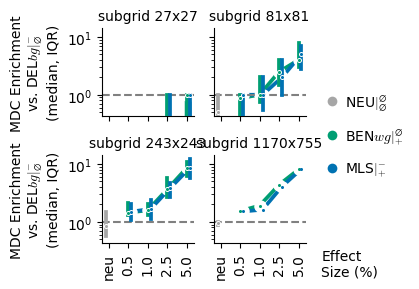

In [ ]:
with tp.teed(
    sns.catplot,
    data=del_enrichment,
    x="effect_size",
    y="fold_enrichment_del",
    order=effect_size_order,
    hue="kind",
    hue_order=del_kind_order,
    palette=kind_palette,
    col="pop_size",
    col_order=pop_size_order,
    col_wrap=2,
    kind="point",
    estimator="median",
    errorbar=("pi", 50),
    dodge=0.3,
    height=1.5,
    aspect=1.1,
    teeplot_outattrs={"normalization": "DELbg"},
    teeplot_outexclude=[
        "palette",
        "hue_order",
        "col_order",
        "col_wrap",
        "dodge",
        "order",
    ],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    gap_points(*_g.axes.flat, _g.legend)
    _g.refline(y=1, color="gray", linestyle="--")
    _g.set(yscale="log")
    _g.set_axis_labels(
        "",
        f"MDC Enrichment\nvs. {kind_labels['DELbg']}\n(median, IQR)",
    )
    _g.set_titles(col_template="subgrid {col_name}")
    for _a in _g.axes.flat:
        plt.setp(
            _a.get_xticklabels(),
            rotation=90,
            ha="right",
            va="center",
            rotation_mode="anchor",
        )
    corner_xlabel(_g, right_legend(_g))
plt.close("all")